In [1]:
import spatialdata as sd
import decoupler as dc
from spatialdata_io import xenium
from collections import defaultdict

import numpy as np
import pandas as pd
import scipy.sparse as sp


import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

import scanpy as sc

import squidpy as sq

sc.set_figure_params(figsize=(8,8))
mpl.rcParams['figure.dpi'] = 200

import os

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
Sample_895=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_895.h5ad")
Sample_894=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_894.h5ad")
Sample_898=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_898.h5ad")


Sample_896=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_896.h5ad")
Sample_897=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_897.h5ad")
Sample_18=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_18.h5ad")

Sample_886=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_886.h5ad")
Sample_890=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_890.h5ad")
Sample_891=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_891.h5ad")


Sample_4=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_4.h5ad")
Sample_5=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_5.h5ad")
Sample_3=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_3.h5ad")


In [3]:
adata = Sample_886.concatenate(Sample_890, Sample_891)

In [4]:
sc.pp.normalize_total(adata, target_sum=1e4)  # Normalize per cell
sc.pp.log1p(adata)  # Log transformation (natural log)

In [5]:
# Define threshold (typically 0, but adjust if needed)
gene = "DystrophinExon50_53"
threshold = 0  # Can be adjusted based on data distribution

# Identify positive and negative groups
adata.obs['Skipping_Positive'] = adata[:, gene].X.toarray().flatten() > threshold

# Rename boolean categories to "Positive" and "Negative"
adata.obs['Skipping_Positive'] = adata.obs['Skipping_Positive'].replace({True: "Positive", False: "Negative"})

# Convert to categorical type
adata.obs['Skipping_Positive'] = adata.obs['Skipping_Positive'].astype("category")

# Check the renamed categories
print(adata.obs['Skipping_Positive'].value_counts())

Skipping_Positive
Negative    229643
Positive       811
Name: count, dtype: int64


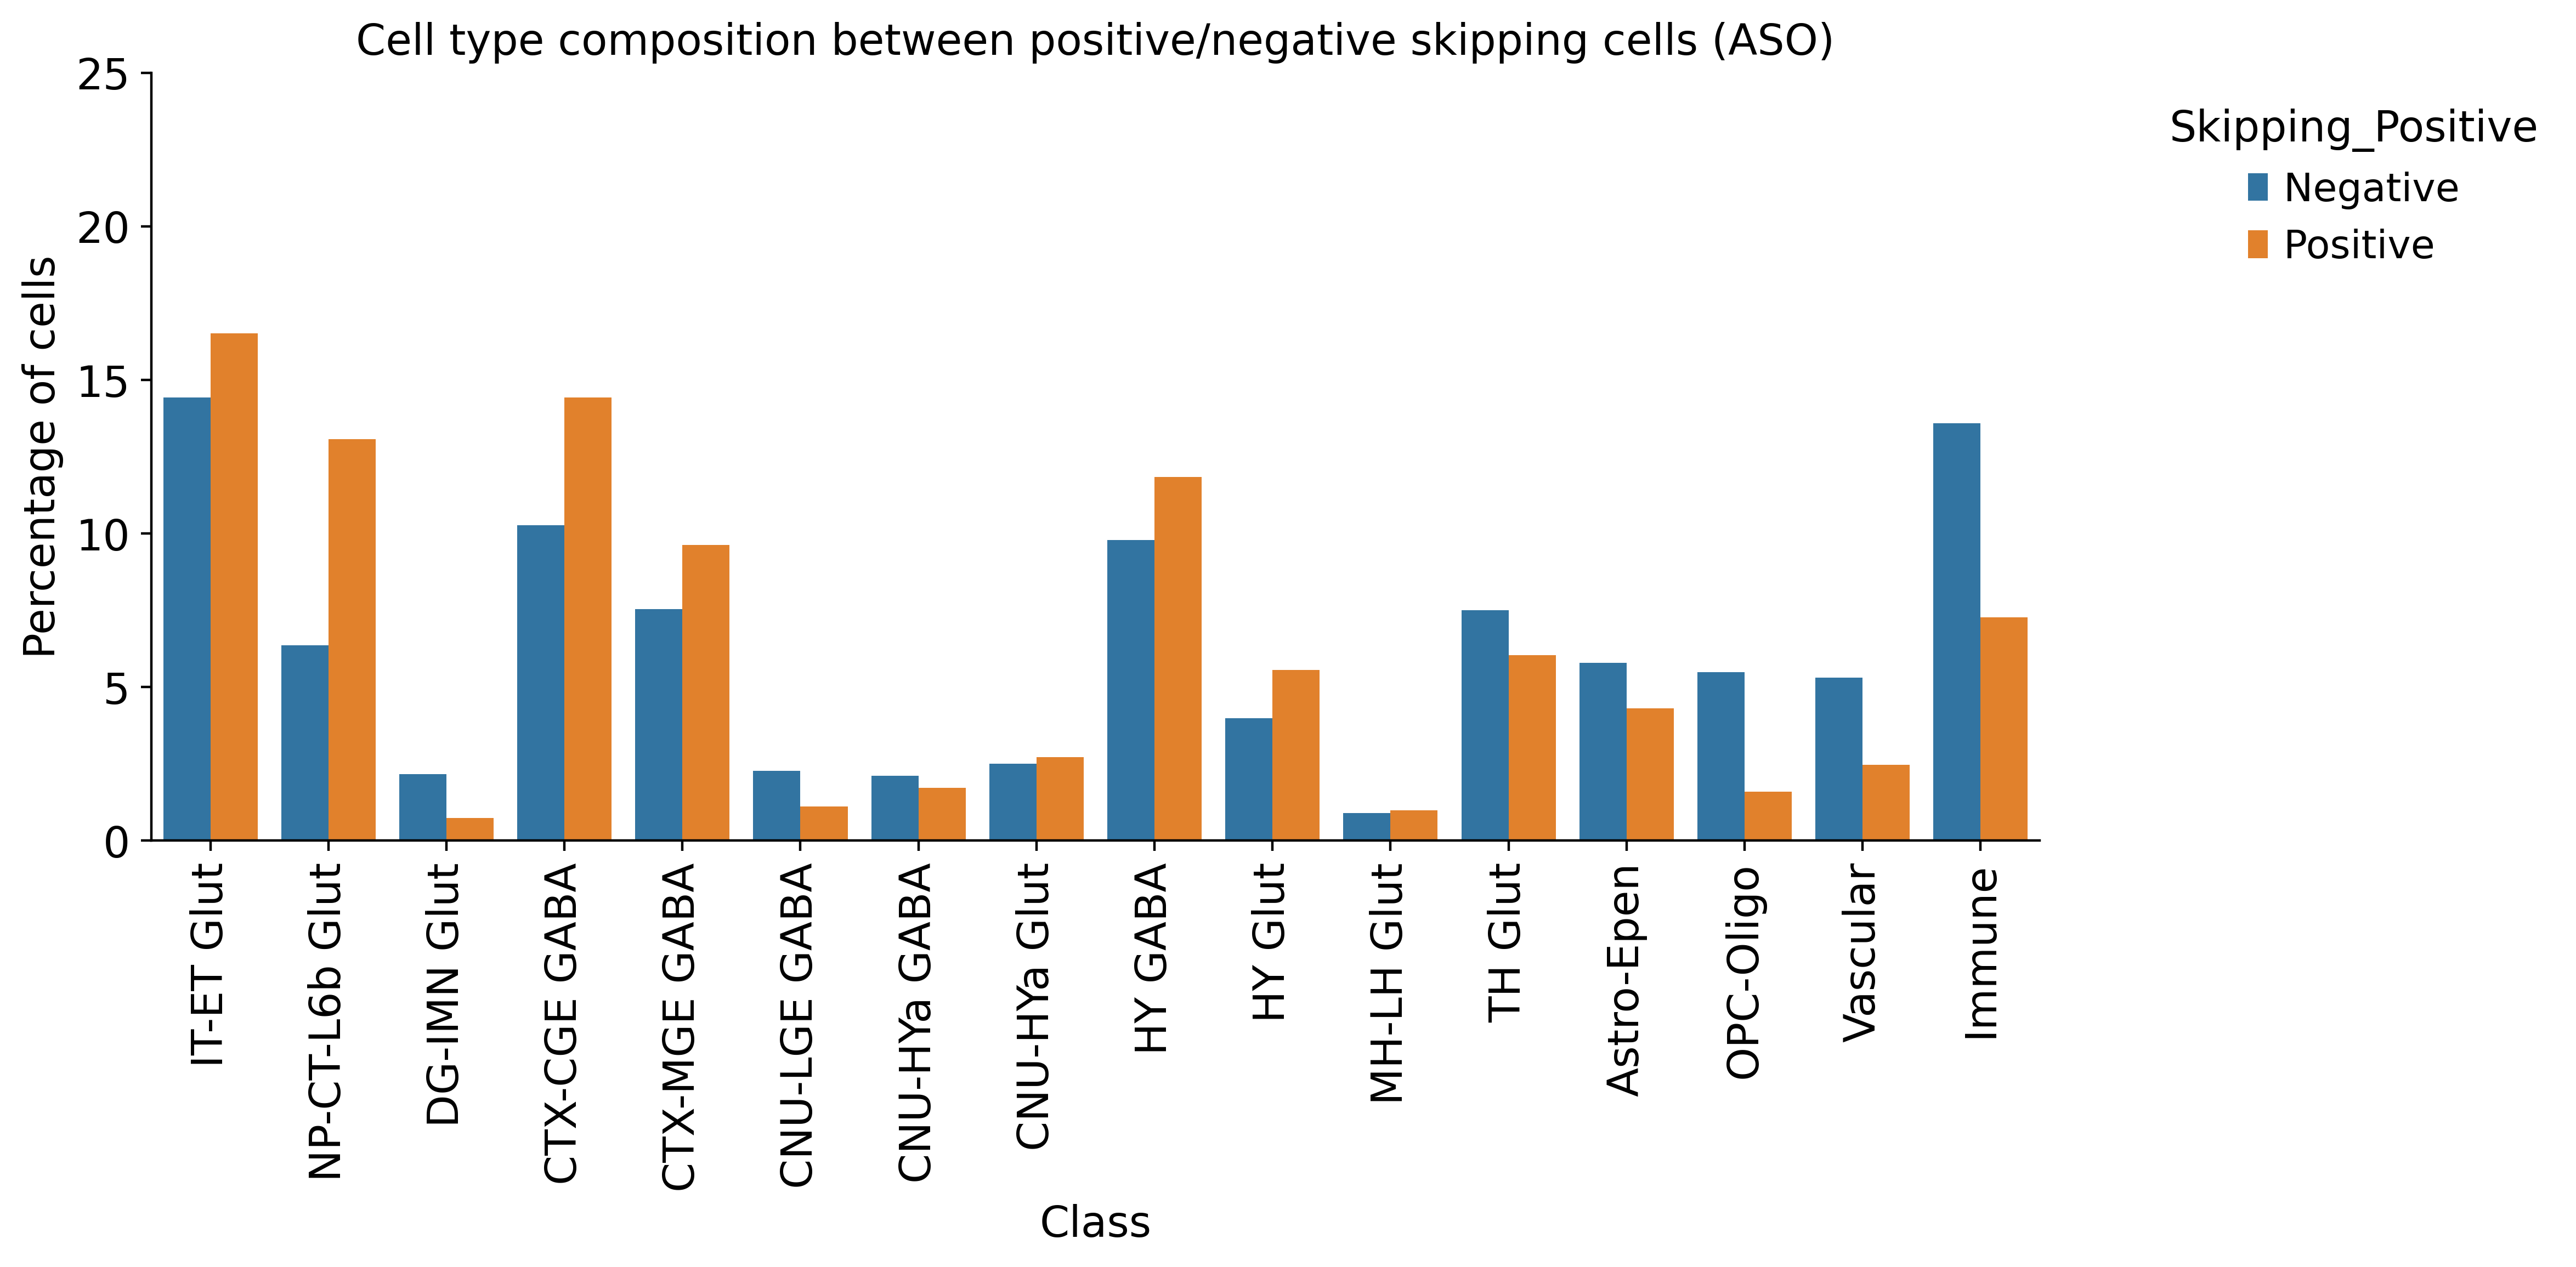

In [23]:
# Step 1: Melt the percentage dataframe to long format
df_melted = percent_df.reset_index().melt(
    id_vars=group_col,
    var_name=celltype_col,
    value_name='Percentage'
)

# Step 2: Create the barplot
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df_melted,
    x=celltype_col,
    y='Percentage',
    hue=group_col,
    dodge=True,
    palette='tab10',
    edgecolor='none'  # cleaner bars
)

# Step 3: Clean and annotate
ax.set_ylabel('Percentage of cells')
ax.set_xlabel(celltype_col)
ax.set_title('Cell type composition between positive/negative skipping cells (ASO)')

# Rotate x-axis labels if needed
plt.xticks(rotation=90)

# Remove gridlines
ax.grid(False)

# Remove top and right spines
sns.despine(ax=ax)

# Move legend outside
ax.legend(title=group_col, bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)

ax.set_ylim(0, 25)

# Tight layout to prevent clipping
plt.tight_layout()
plt.show()

In [6]:
def stratified_match_sample(ref_df, target_df, stratify_cols, random_state=None):
    """
    Sample from ref_df to match the stratified distribution of target_df.
    
    Parameters:
    - ref_df: pandas DataFrame to sample from (e.g., rest.obs)
    - target_df: pandas DataFrame to match (e.g., pop1.obs)
    - stratify_cols: list of column names to match on (e.g., ['cell_type', 'region'])
    - random_state: for reproducibility
    
    Returns:
    - indices (Index): Index of sampled rows from ref_df
    """
    rng = np.random.default_rng(seed=random_state)
    sampled_indices = []

    # Count how many cells for each group in target_df
    group_sizes = target_df.groupby(stratify_cols).size()

    for group, n in group_sizes.items():
        if isinstance(group, str):
            group = (group,)
        mask = np.logical_and.reduce([
            ref_df[col] == val for col, val in zip(stratify_cols, group)
        ])
        eligible = ref_df[mask]

        if len(eligible) < n:
            raise ValueError(f"Not enough samples in ref_df for group {group}. Needed {n}, found {len(eligible)}.")

        sampled_indices.extend(rng.choice(eligible.index, size=n, replace=False))

    return pd.Index(sampled_indices)

In [7]:
import scanpy as sc
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import tqdm

# Define groups
pop1 = adata[adata.obs['Skipping_Positive'] == 'Positive']
rest = adata[adata.obs['Skipping_Positive'] == 'Negative']

# Count reference population by (Class, Region)
joint_counts = pop1.obs.groupby(['Class', 'Region']).size()

# Gene names
gene_names = adata.var_names
pval_threshold = 0.05
n_permutations = 1000
max_usage_per_cell = 5

print("Precomputing exact pools...")
exact_pools = {
    (cls, reg): rest.obs.query("Class == @cls and Region == @reg").index.tolist()
    for (cls, reg) in joint_counts.index
}

print("Precomputing class pools...")
class_pools = {
    cls: rest.obs.query("Class == @cls").index.tolist()
    for cls in rest.obs['Class'].unique()
}

print("Precomputing region pools...")
region_pools = {
    reg: rest.obs.query("Region == @reg").index.tolist()
    for reg in rest.obs['Region'].unique()
}

print("All pool indices...")
all_pool = rest.obs.index.tolist()

# Initialize usage tracking dict
cell_usage = defaultdict(int)

# Initialize results containers
gene_pvals = defaultdict(list)
gene_logfc = defaultdict(list)
gene_sig_counts = defaultdict(int)

# Jaccard tracking
jaccard_stats = []
prev_sig_genes = set()
prev_top_logfc_genes = set()

# Helper: filter cells by usage and exclusion list
def filter_by_usage(indices, usage, exclude_set, max_usage):
    return [idx for idx in indices if idx not in exclude_set and usage[idx] < max_usage]

for i in tqdm(range(n_permutations), desc="Permutations"):
    sampled_indices = []
    skip = False

    for (cls, reg), count in joint_counts.items():
        exclude_indices = set(pop1.obs_names).union(sampled_indices)
        needed = count
        sampled = []

        # Exact pool
        exact_candidates = filter_by_usage(exact_pools.get((cls, reg), []), cell_usage, exclude_indices, max_usage_per_cell)
        take = min(len(exact_candidates), needed)
        if take > 0:
            sampled.extend(np.random.choice(exact_candidates, take, replace=False))
            needed -= take

        # Fallbacks
        for pool_dict, key in [(class_pools, cls), (region_pools, reg), ({'all': all_pool}, 'all')]:
            if needed == 0:
                break
            fallback_candidates = filter_by_usage(pool_dict.get(key, []), cell_usage, exclude_indices.union(sampled), max_usage_per_cell)
            take = min(len(fallback_candidates), needed)
            if take > 0:
                sampled.extend(np.random.choice(fallback_candidates, take, replace=False))
                needed -= take

        if needed > 0:
            print(f"Iteration {i}, Class {cls}, Region {reg}: Not enough cells to sample ({count-needed}/{count}), skipping permutation")
            skip = True
            break

        sampled_indices.extend(sampled)

    if skip or len(sampled_indices) != pop1.n_obs:
        continue

    for idx in sampled_indices:
        cell_usage[idx] += 1

    rest_sampled = rest[sampled_indices]
    combined = pop1.concatenate(rest_sampled, batch_key=None)
    combined.obs['pop_vs_rest'] = ['pop1'] * pop1.n_obs + ['rest'] * rest_sampled.n_obs

    sc.tl.rank_genes_groups(
        combined,
        groupby='pop_vs_rest',
        groups=['pop1'],
        reference='rest',
        method='wilcoxon',
        n_genes=combined.shape[1],
        use_raw=False
    )

    result_df = sc.get.rank_genes_groups_df(combined, group='pop1')

    for _, row in result_df.iterrows():
        gene = row['names']
        fc = row['logfoldchanges']
        p = row['pvals']

        gene_logfc[gene].append(fc)
        gene_pvals[gene].append(p)
        if p < pval_threshold:
            gene_sig_counts[gene] += 1

    # Compute Jaccard every 10 loops
    if (i + 1) % 10 == 0: 
        current_sig_genes = {g for g in gene_names if gene_sig_counts[g] >= 10} ## (i + 1)
        avg_logfc = {
            g: np.mean(gene_logfc[g]) for g in gene_names if gene_logfc[g]
        }
        current_top_logfc_genes = set(
            sorted(avg_logfc, key=avg_logfc.get, reverse=True)[:30]
        )

        def jaccard(set1, set2):
            if not set1 and not set2:
                return 1.0
            return len(set1 & set2) / len(set1 | set2)

        jaccard_stats.append({
            'iteration': i + 1,
            'jaccard_significant': jaccard(prev_sig_genes, current_sig_genes),
            'jaccard_logfc': jaccard(prev_top_logfc_genes, current_top_logfc_genes),
            'n_sig_genes': len(current_sig_genes)
        })

        prev_sig_genes = current_sig_genes
        prev_top_logfc_genes = current_top_logfc_genes

# Final summary
summary_df = pd.DataFrame({
    'Gene': gene_names,
    'Avg_LogFC': [np.mean(gene_logfc[gene]) if gene_logfc[gene] else np.nan for gene in gene_names],
    'Significance_Count': [gene_sig_counts[gene] for gene in gene_names]
}).sort_values(by='Significance_Count', ascending=False)

jaccard_df = pd.DataFrame(jaccard_stats)
print("Permutation test completed.")


Precomputing exact pools...
Precomputing class pools...
Precomputing region pools...
All pool indices...


Permutations: 100%|██████████| 1000/1000 [06:49<00:00,  2.44it/s]

Permutation test completed.


In [18]:
genes_of_interest = ["DystrophinExon50_53","DystrophinExon50_51","DystrophinExon51_53","Dp427c", "Dp427m","Dp427p","Dp71_Dp40_firstexon","Dp40","Dystrophin_Exon2_29","Dystrophin_Exon30_44","Dystrophin_Exon56_62","Dystrophin_Exon79"]
filtered_df = summary_df[summary_df["Gene"].isin(genes_of_interest)]
filtered_df = filtered_df.set_index("Gene").loc[genes_of_interest].reset_index()

In [19]:
filtered_df 

,Gene,Avg_LogFC,Significance_Count
0,DystrophinExon50_53,34.430511,1000
1,DystrophinExon50_51,0.264779,0
2,DystrophinExon51_53,-0.161926,0
3,Dp427c,0.725000,997
4,Dp427m,0.553746,340
5,Dp427p,0.558893,104
6,Dp71_Dp40_firstexon,0.392693,37
7,Dp40,-0.002207,0
8,Dystrophin_Exon2_29,0.734766,999
9,Dystrophin_Exon30_44,0.913685,1000


/tmp/ipykernel_2912629/1822258505.py:125: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.95])


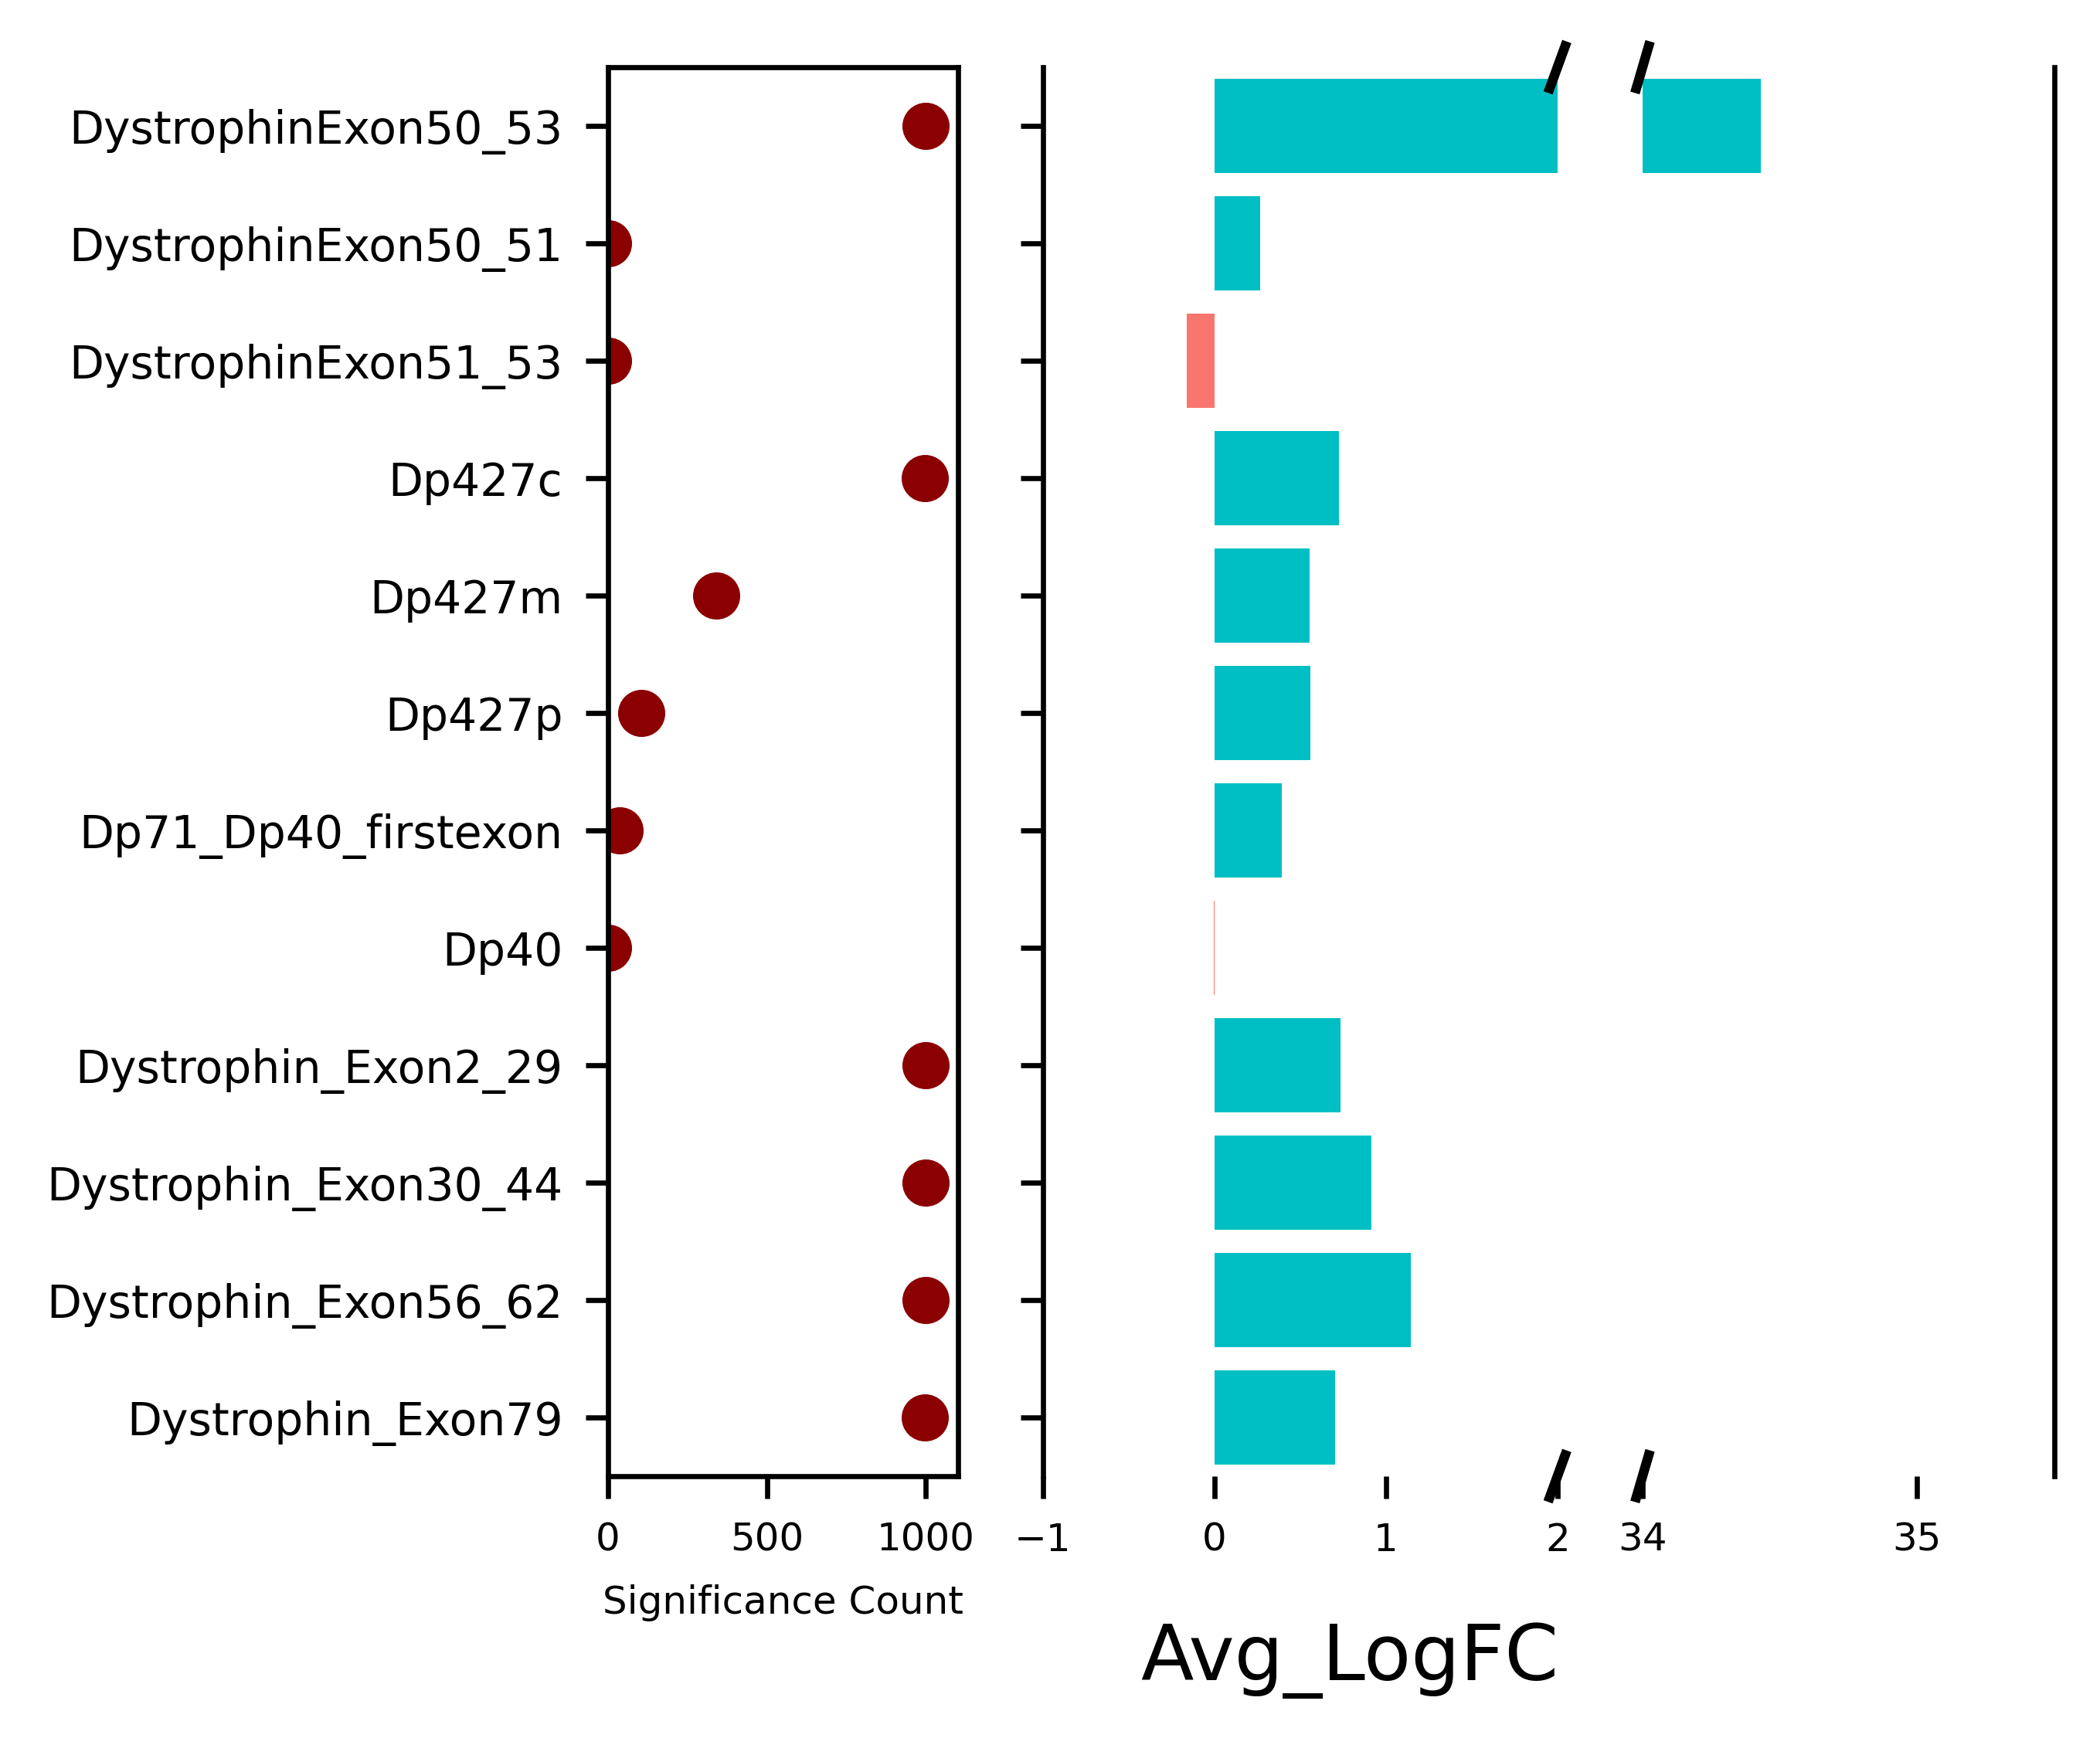

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MaxNLocator


# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 4,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 7,
    'legend.fontsize': 6
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'


##df=summary_df[summary_df["Significance_Count"]>900].sort_values(by='Avg_LogFC',ascending=False).head(30)

##df = summary_df[summary_df["Significance_Count"] > 900] \
##    .sort_values(by='Avg_LogFC', key=lambda x: x.abs(), ascending=False) \
##    .head(30)

df_sorted=filtered_df

# Sort genes by descending Avg_LogFC
##df_sorted = df.sort_values("Avg_LogFC", ascending=False).reset_index(drop=True)

# Set thresholds
low_max = 2
high_min = 34

# Colors
dot_color = 'darkred'  # dotplot color
bar_colors_neg = "#f8766d"  # negative bars
bar_colors_pos = "#00bfc4"  # positive bars

gene_order = df_sorted["Gene"]

# Masks for barplot ranges
low_mask = df_sorted['Avg_LogFC'] <= low_max
high_mask = df_sorted['Avg_LogFC'] >= high_min

# Create figure and GridSpec with larger spacing
fig = plt.figure(figsize=(4, 4))
gs = gridspec.GridSpec(1, 3, width_ratios=[1.7, 2.5, 2], wspace=0.2)

# Axes
ax_dot = fig.add_subplot(gs[0])
ax_bar_low = fig.add_subplot(gs[1], sharey=ax_dot)
ax_bar_high = fig.add_subplot(gs[2], sharey=ax_dot)

# --- Dot plot ---
ax_dot.scatter(df_sorted["Significance_Count"], df_sorted["Gene"], color=dot_color, s=40)
ax_dot.set_xlabel("Significance Count")
ax_dot.set_facecolor("white")
ax_dot.set_xlim(0, df_sorted["Significance_Count"].max() * 1.1)
ax_dot.grid(False)
for spine in ax_dot.spines.values():
    spine.set_visible(True)

# --- Bar plot (broken x-axis) ---

# Bar colors: negative and positive separately
bar_colors = [bar_colors_neg if val < 0 else bar_colors_pos for val in df_sorted['Avg_LogFC']]

# Low range barplot (-5 to 2)
ax_bar_low.barh(
    gene_order,
    df_sorted['Avg_LogFC'],
    color=bar_colors
)
ax_bar_low.set_xlim(-1, low_max)
ax_bar_low.set_facecolor("white")
ax_bar_low.tick_params(axis='y', labelleft=False)
ax_bar_low.spines['top'].set_visible(False)
ax_bar_low.spines['bottom'].set_visible(False)
ax_bar_low.spines['right'].set_visible(False)
ax_bar_low.grid(False)
ax_bar_low.xaxis.set_major_locator(MaxNLocator(integer=True))

# High range barplot (>= 30)
bar_heights = np.where(high_mask, df_sorted['Avg_LogFC'], 0)
ax_bar_high.barh(
    gene_order,
    bar_heights,
    color=bar_colors
)
ax_bar_high.set_xlim(high_min, int(np.ceil(df_sorted['Avg_LogFC'].max())) + 0.5)
ax_bar_high.set_facecolor("white")
ax_bar_high.tick_params(axis='y', labelleft=False, left=False)
ax_bar_high.spines['top'].set_visible(False)
ax_bar_high.spines['bottom'].set_visible(False)
ax_bar_high.spines['left'].set_visible(False)
ax_bar_high.grid(False)
ax_bar_high.xaxis.set_major_locator(MaxNLocator(integer=True))

# --- Broken axis diagonal lines ---
d = .015
kwargs = dict(transform=ax_bar_low.transAxes, color='k', clip_on=False)
ax_bar_low.plot((1 - d, 1 + d), (-d, +d), **kwargs)
ax_bar_low.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

kwargs.update(transform=ax_bar_high.transAxes)
ax_bar_high.plot((-d, +d), (-d, +d), **kwargs)
ax_bar_high.plot((-d, +d), (1 - d, 1 + d), **kwargs)

# --- Fix y-axis limits to remove gap ---
ax_dot.set_ylim(-0.5, len(gene_order) - 0.5)
ax_bar_low.set_ylim(-0.5, len(gene_order) - 0.5)
ax_bar_high.set_ylim(-0.5, len(gene_order) - 0.5)

# Invert y-axis for all to keep gene order top-to-bottom
ax_dot.invert_yaxis()

# Labels and title
fig.text(0.58, 0.04, 'Avg_LogFC', ha='center', fontsize=12)
##plt.suptitle("Permutation Test: Significance Count & Avg_LogFC (Broken Bar Axis)", fontsize=14)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])

plt.savefig(f"/exports/humgen/qmao/Skipping_DE_ASO.svg",format="svg",dpi=300, bbox_inches='tight')

plt.show()

In [3]:
adata = Sample_4.concatenate(Sample_5, Sample_3)

In [4]:
sc.pp.normalize_total(adata, target_sum=1e4)  # Normalize per cell
sc.pp.log1p(adata)  # Log transformation (natural log)

In [7]:
# Define threshold (typically 0, but adjust if needed)
gene = "DystrophinExon50_53"
threshold = 0  # Can be adjusted based on data distribution

# Identify positive and negative groups
adata.obs['Skipping_Positive'] = adata[:, gene].X.toarray().flatten() > threshold

# Rename boolean categories to "Positive" and "Negative"
adata.obs['Skipping_Positive'] = adata.obs['Skipping_Positive'].replace({True: "Positive", False: "Negative"})

# Convert to categorical type
adata.obs['Skipping_Positive'] = adata.obs['Skipping_Positive'].astype("category")

# Check the renamed categories
print(adata.obs['Skipping_Positive'].value_counts())

Skipping_Positive
Negative    217916
Positive      1299
Name: count, dtype: int64


In [8]:
# Step 1: Melt the percentage dataframe to long format
df_melted = percent_df.reset_index().melt(
    id_vars=group_col,
    var_name=celltype_col,
    value_name='Percentage'
)

# Step 2: Create the barplot
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df_melted,
    x=celltype_col,
    y='Percentage',
    hue=group_col,
    dodge=True,
    palette='tab10',
    edgecolor='none'  # cleaner bars
)

# Step 3: Clean and annotate
ax.set_ylabel('Percentage of cells')
ax.set_xlabel(celltype_col)
ax.set_title('Cell type composition between positive/negative skipping cells (U7ex51)')

# Rotate x-axis labels if needed
plt.xticks(rotation=90)

# Remove gridlines
ax.grid(False)

# Remove top and right spines
sns.despine(ax=ax)

# Move legend outside
ax.legend(title=group_col, bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)

# Tight layout to prevent clipping
plt.tight_layout()
plt.show()

NameError: name 'percent_df' is not defined

In [9]:
def stratified_match_sample(ref_df, target_df, stratify_cols, random_state=None):
    """
    Sample from ref_df to match the stratified distribution of target_df.
    
    Parameters:
    - ref_df: pandas DataFrame to sample from (e.g., rest.obs)
    - target_df: pandas DataFrame to match (e.g., pop1.obs)
    - stratify_cols: list of column names to match on (e.g., ['cell_type', 'region'])
    - random_state: for reproducibility
    
    Returns:
    - indices (Index): Index of sampled rows from ref_df
    """
    rng = np.random.default_rng(seed=random_state)
    sampled_indices = []

    # Count how many cells for each group in target_df
    group_sizes = target_df.groupby(stratify_cols).size()

    for group, n in group_sizes.items():
        if isinstance(group, str):
            group = (group,)
        mask = np.logical_and.reduce([
            ref_df[col] == val for col, val in zip(stratify_cols, group)
        ])
        eligible = ref_df[mask]

        if len(eligible) < n:
            raise ValueError(f"Not enough samples in ref_df for group {group}. Needed {n}, found {len(eligible)}.")

        sampled_indices.extend(rng.choice(eligible.index, size=n, replace=False))

    return pd.Index(sampled_indices)

In [10]:
import scanpy as sc
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import tqdm

# Define groups
pop1 = adata[adata.obs['Skipping_Positive'] == 'Positive']
rest = adata[adata.obs['Skipping_Positive'] == 'Negative']

# Count reference population by (Class, Region)
joint_counts = pop1.obs.groupby(['Class', 'Region']).size()

# Gene names
gene_names = adata.var_names
pval_threshold = 0.05
n_permutations = 1000
max_usage_per_cell = 7

print("Precomputing exact pools...")
exact_pools = {
    (cls, reg): rest.obs.query("Class == @cls and Region == @reg").index.tolist()
    for (cls, reg) in joint_counts.index
}

print("Precomputing class pools...")
class_pools = {
    cls: rest.obs.query("Class == @cls").index.tolist()
    for cls in rest.obs['Class'].unique()
}

print("Precomputing region pools...")
region_pools = {
    reg: rest.obs.query("Region == @reg").index.tolist()
    for reg in rest.obs['Region'].unique()
}

print("All pool indices...")
all_pool = rest.obs.index.tolist()

# Initialize usage tracking dict
cell_usage = defaultdict(int)

# Initialize results containers
gene_pvals = defaultdict(list)
gene_logfc = defaultdict(list)
gene_sig_counts = defaultdict(int)

# Jaccard tracking
jaccard_stats = []
prev_sig_genes = set()
prev_top_logfc_genes = set()

# Helper: filter cells by usage and exclusion list
def filter_by_usage(indices, usage, exclude_set, max_usage):
    return [idx for idx in indices if idx not in exclude_set and usage[idx] < max_usage]

for i in tqdm(range(n_permutations), desc="Permutations"):
    sampled_indices = []
    skip = False

    for (cls, reg), count in joint_counts.items():
        exclude_indices = set(pop1.obs_names).union(sampled_indices)
        needed = count
        sampled = []

        # Exact pool
        exact_candidates = filter_by_usage(exact_pools.get((cls, reg), []), cell_usage, exclude_indices, max_usage_per_cell)
        take = min(len(exact_candidates), needed)
        if take > 0:
            sampled.extend(np.random.choice(exact_candidates, take, replace=False))
            needed -= take

        # Fallbacks
        for pool_dict, key in [(class_pools, cls), (region_pools, reg), ({'all': all_pool}, 'all')]:
            if needed == 0:
                break
            fallback_candidates = filter_by_usage(pool_dict.get(key, []), cell_usage, exclude_indices.union(sampled), max_usage_per_cell)
            take = min(len(fallback_candidates), needed)
            if take > 0:
                sampled.extend(np.random.choice(fallback_candidates, take, replace=False))
                needed -= take

        if needed > 0:
            print(f"Iteration {i}, Class {cls}, Region {reg}: Not enough cells to sample ({count-needed}/{count}), skipping permutation")
            skip = True
            break

        sampled_indices.extend(sampled)

    if skip or len(sampled_indices) != pop1.n_obs:
        continue

    for idx in sampled_indices:
        cell_usage[idx] += 1

    rest_sampled = rest[sampled_indices]
    combined = pop1.concatenate(rest_sampled, batch_key=None)
    combined.obs['pop_vs_rest'] = ['pop1'] * pop1.n_obs + ['rest'] * rest_sampled.n_obs

    sc.tl.rank_genes_groups(
        combined,
        groupby='pop_vs_rest',
        groups=['pop1'],
        reference='rest',
        method='wilcoxon',
        n_genes=combined.shape[1],
        use_raw=False
    )

    result_df = sc.get.rank_genes_groups_df(combined, group='pop1')

    for _, row in result_df.iterrows():
        gene = row['names']
        fc = row['logfoldchanges']
        p = row['pvals']

        gene_logfc[gene].append(fc)
        gene_pvals[gene].append(p)
        if p < pval_threshold:
            gene_sig_counts[gene] += 1

    # Compute Jaccard every 10 loops
    if (i + 1) % 10 == 0: 
        current_sig_genes = {g for g in gene_names if gene_sig_counts[g] >= 10} ## (i + 1)
        avg_logfc = {
            g: np.mean(gene_logfc[g]) for g in gene_names if gene_logfc[g]
        }
        current_top_logfc_genes = set(
            sorted(avg_logfc, key=avg_logfc.get, reverse=True)[:30]
        )

        def jaccard(set1, set2):
            if not set1 and not set2:
                return 1.0
            return len(set1 & set2) / len(set1 | set2)

        jaccard_stats.append({
            'iteration': i + 1,
            'jaccard_significant': jaccard(prev_sig_genes, current_sig_genes),
            'jaccard_logfc': jaccard(prev_top_logfc_genes, current_top_logfc_genes),
            'n_sig_genes': len(current_sig_genes)
        })

        prev_sig_genes = current_sig_genes
        prev_top_logfc_genes = current_top_logfc_genes

# Final summary
summary_df = pd.DataFrame({
    'Gene': gene_names,
    'Avg_LogFC': [np.mean(gene_logfc[gene]) if gene_logfc[gene] else np.nan for gene in gene_names],
    'Significance_Count': [gene_sig_counts[gene] for gene in gene_names]
}).sort_values(by='Significance_Count', ascending=False)

jaccard_df = pd.DataFrame(jaccard_stats)
print("Permutation test completed.")

Precomputing exact pools...
Precomputing class pools...
Precomputing region pools...
All pool indices...


Permutations: 100%|██████████| 1000/1000 [16:47<00:00,  1.01s/it]

Permutation test completed.


/tmp/ipykernel_2669814/3690995225.py:121: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.95])


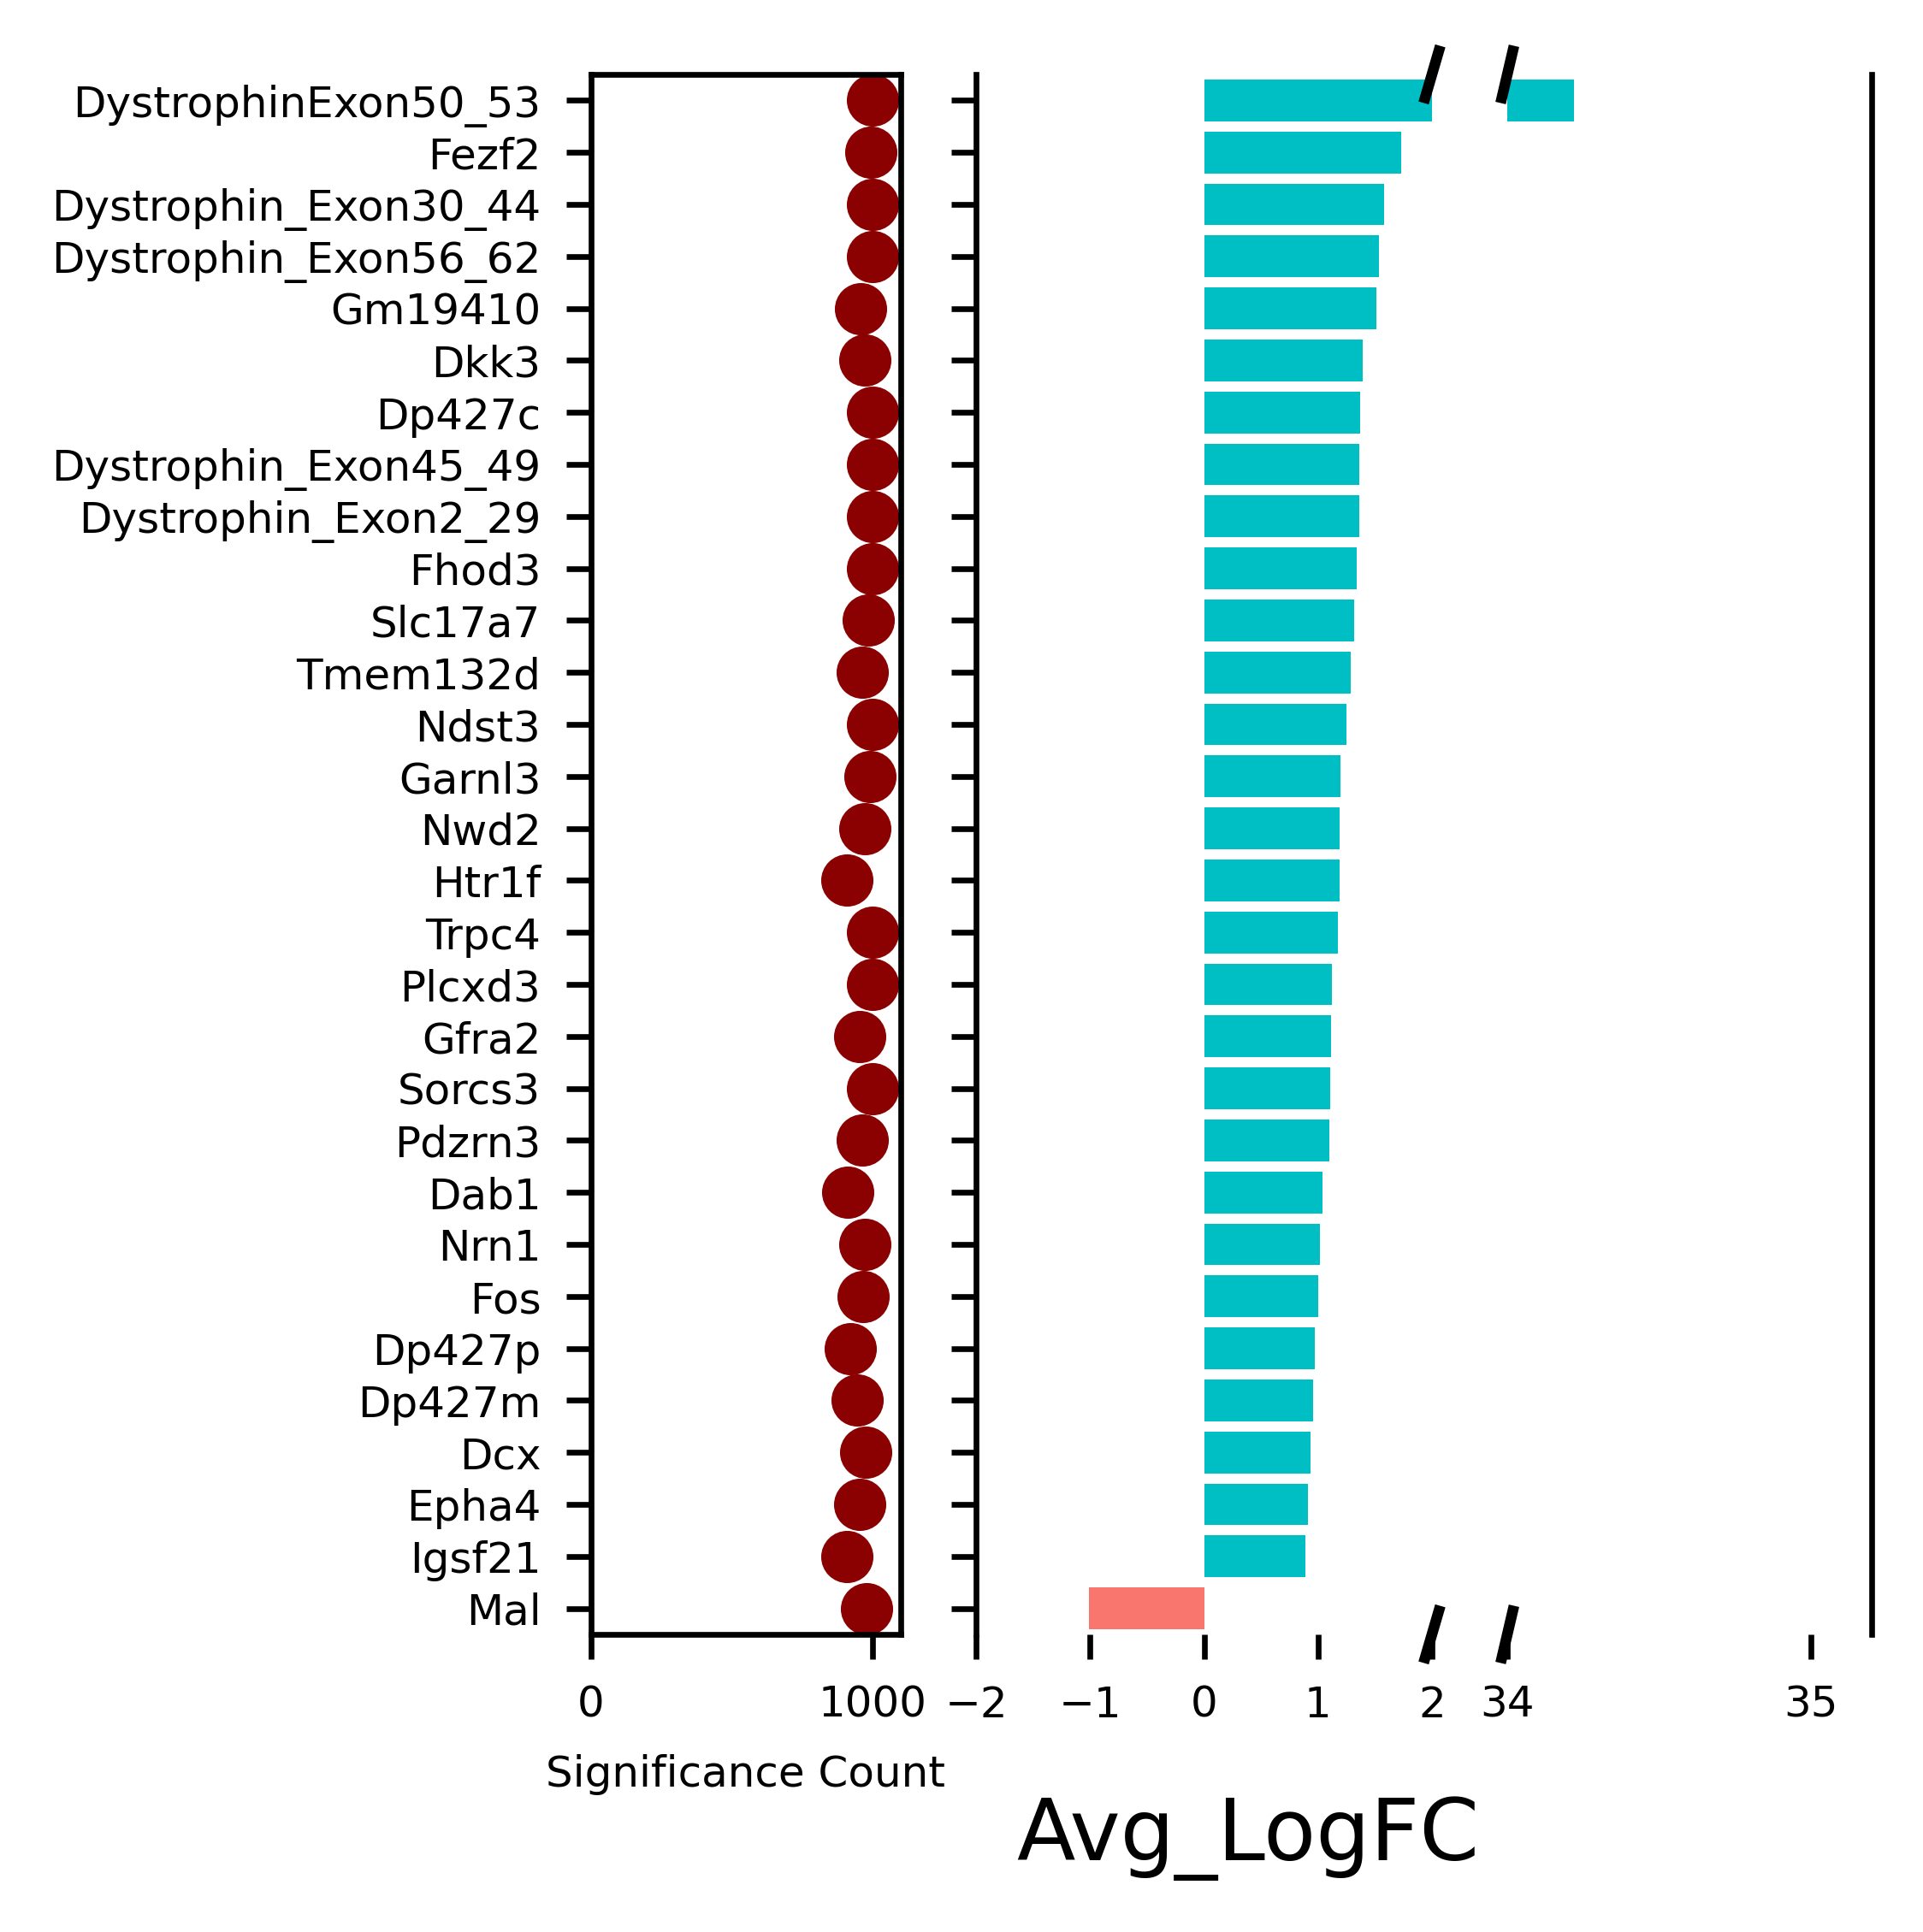

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MaxNLocator


# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 4,
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'


df = summary_df[summary_df["Significance_Count"] > 900] \
    .sort_values(by='Avg_LogFC', key=lambda x: x.abs(), ascending=False) \
    .head(30)

# Sort genes by descending Avg_LogFC
df_sorted = df.sort_values("Avg_LogFC", ascending=False).reset_index(drop=True)

# Set thresholds
low_max = 2
high_min = 34

# Colors
dot_color = 'darkred'  # dotplot color
bar_colors_neg = "#f8766d"  # negative bars
bar_colors_pos = "#00bfc4"  # positive bars

gene_order = df_sorted["Gene"]

# Masks for barplot ranges
low_mask = df_sorted['Avg_LogFC'] <= low_max
high_mask = df_sorted['Avg_LogFC'] >= high_min

# Create figure and GridSpec with larger spacing
fig = plt.figure(figsize=(3.2, 4))
gs = gridspec.GridSpec(1, 3, width_ratios=[1.7, 2.5, 2], wspace=0.2)

# Axes
ax_dot = fig.add_subplot(gs[0])
ax_bar_low = fig.add_subplot(gs[1], sharey=ax_dot)
ax_bar_high = fig.add_subplot(gs[2], sharey=ax_dot)

# --- Dot plot ---
ax_dot.scatter(df_sorted["Significance_Count"], df_sorted["Gene"], color=dot_color, s=40)
ax_dot.set_xlabel("Significance Count")
ax_dot.set_facecolor("white")
ax_dot.set_xlim(0, df_sorted["Significance_Count"].max() * 1.1)
ax_dot.grid(False)
for spine in ax_dot.spines.values():
    spine.set_visible(True)

# --- Bar plot (broken x-axis) ---

# Bar colors: negative and positive separately
bar_colors = [bar_colors_neg if val < 0 else bar_colors_pos for val in df_sorted['Avg_LogFC']]

# Low range barplot (-5 to 2)
ax_bar_low.barh(
    gene_order,
    df_sorted['Avg_LogFC'],
    color=bar_colors
)
ax_bar_low.set_xlim(-2, low_max)
ax_bar_low.set_facecolor("white")
ax_bar_low.tick_params(axis='y', labelleft=False)
ax_bar_low.spines['top'].set_visible(False)
ax_bar_low.spines['bottom'].set_visible(False)
ax_bar_low.spines['right'].set_visible(False)
ax_bar_low.grid(False)
ax_bar_low.xaxis.set_major_locator(MaxNLocator(integer=True))

# High range barplot (>= 30)
bar_heights = np.where(high_mask, df_sorted['Avg_LogFC'], 0)
ax_bar_high.barh(
    gene_order,
    bar_heights,
    color=bar_colors
)
ax_bar_high.set_xlim(high_min, int(np.ceil(df_sorted['Avg_LogFC'].max())) + 0.2)
ax_bar_high.set_facecolor("white")
ax_bar_high.tick_params(axis='y', labelleft=False, left=False)
ax_bar_high.spines['top'].set_visible(False)
ax_bar_high.spines['bottom'].set_visible(False)
ax_bar_high.spines['left'].set_visible(False)
ax_bar_high.grid(False)
ax_bar_high.xaxis.set_major_locator(MaxNLocator(integer=True))

# --- Broken axis diagonal lines ---
d = .015
kwargs = dict(transform=ax_bar_low.transAxes, color='k', clip_on=False)
ax_bar_low.plot((1 - d, 1 + d), (-d, +d), **kwargs)
ax_bar_low.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

kwargs.update(transform=ax_bar_high.transAxes)
ax_bar_high.plot((-d, +d), (-d, +d), **kwargs)
ax_bar_high.plot((-d, +d), (1 - d, 1 + d), **kwargs)

# --- Fix y-axis limits to remove gap ---
ax_dot.set_ylim(-0.5, len(gene_order) - 0.5)
ax_bar_low.set_ylim(-0.5, len(gene_order) - 0.5)
ax_bar_high.set_ylim(-0.5, len(gene_order) - 0.5)

# Invert y-axis for all to keep gene order top-to-bottom
ax_dot.invert_yaxis()

# Labels and title
fig.text(0.58, 0.04, 'Avg_LogFC', ha='center', fontsize=12)
##plt.suptitle("Permutation Test: Significance Count & Avg_LogFC (Broken Bar Axis)", fontsize=14)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])

plt.savefig(f"/exports/humgen/qmao/Skipping_DE_U7ex51.svg",format="svg",dpi=300, bbox_inches='tight')

plt.show()

In [54]:
combined.obs["combined"] = combined.obs["pop_vs_rest"].astype(str) + "_" + combined.obs["Class"].astype(str)

In [99]:
expr_df = expr_df.to_df()

AttributeError: 'tuple' object has no attribute 'to_df'

In [100]:
genes = ["Rxfp1"]

expr_df["genes"] = combined.to_df()[genes].copy()
combined.obs["group"] = combined.obs["Class"].astype(str) + "_" + combined.obs["pop_vs_rest"].astype(str)
expr_df["group"] = combined.obs["group"].values

# Pivot: average expression of each gene across group
heatmap_data = expr_df.groupby("group")[genes].mean().T

TypeError: 'tuple' object does not support item assignment

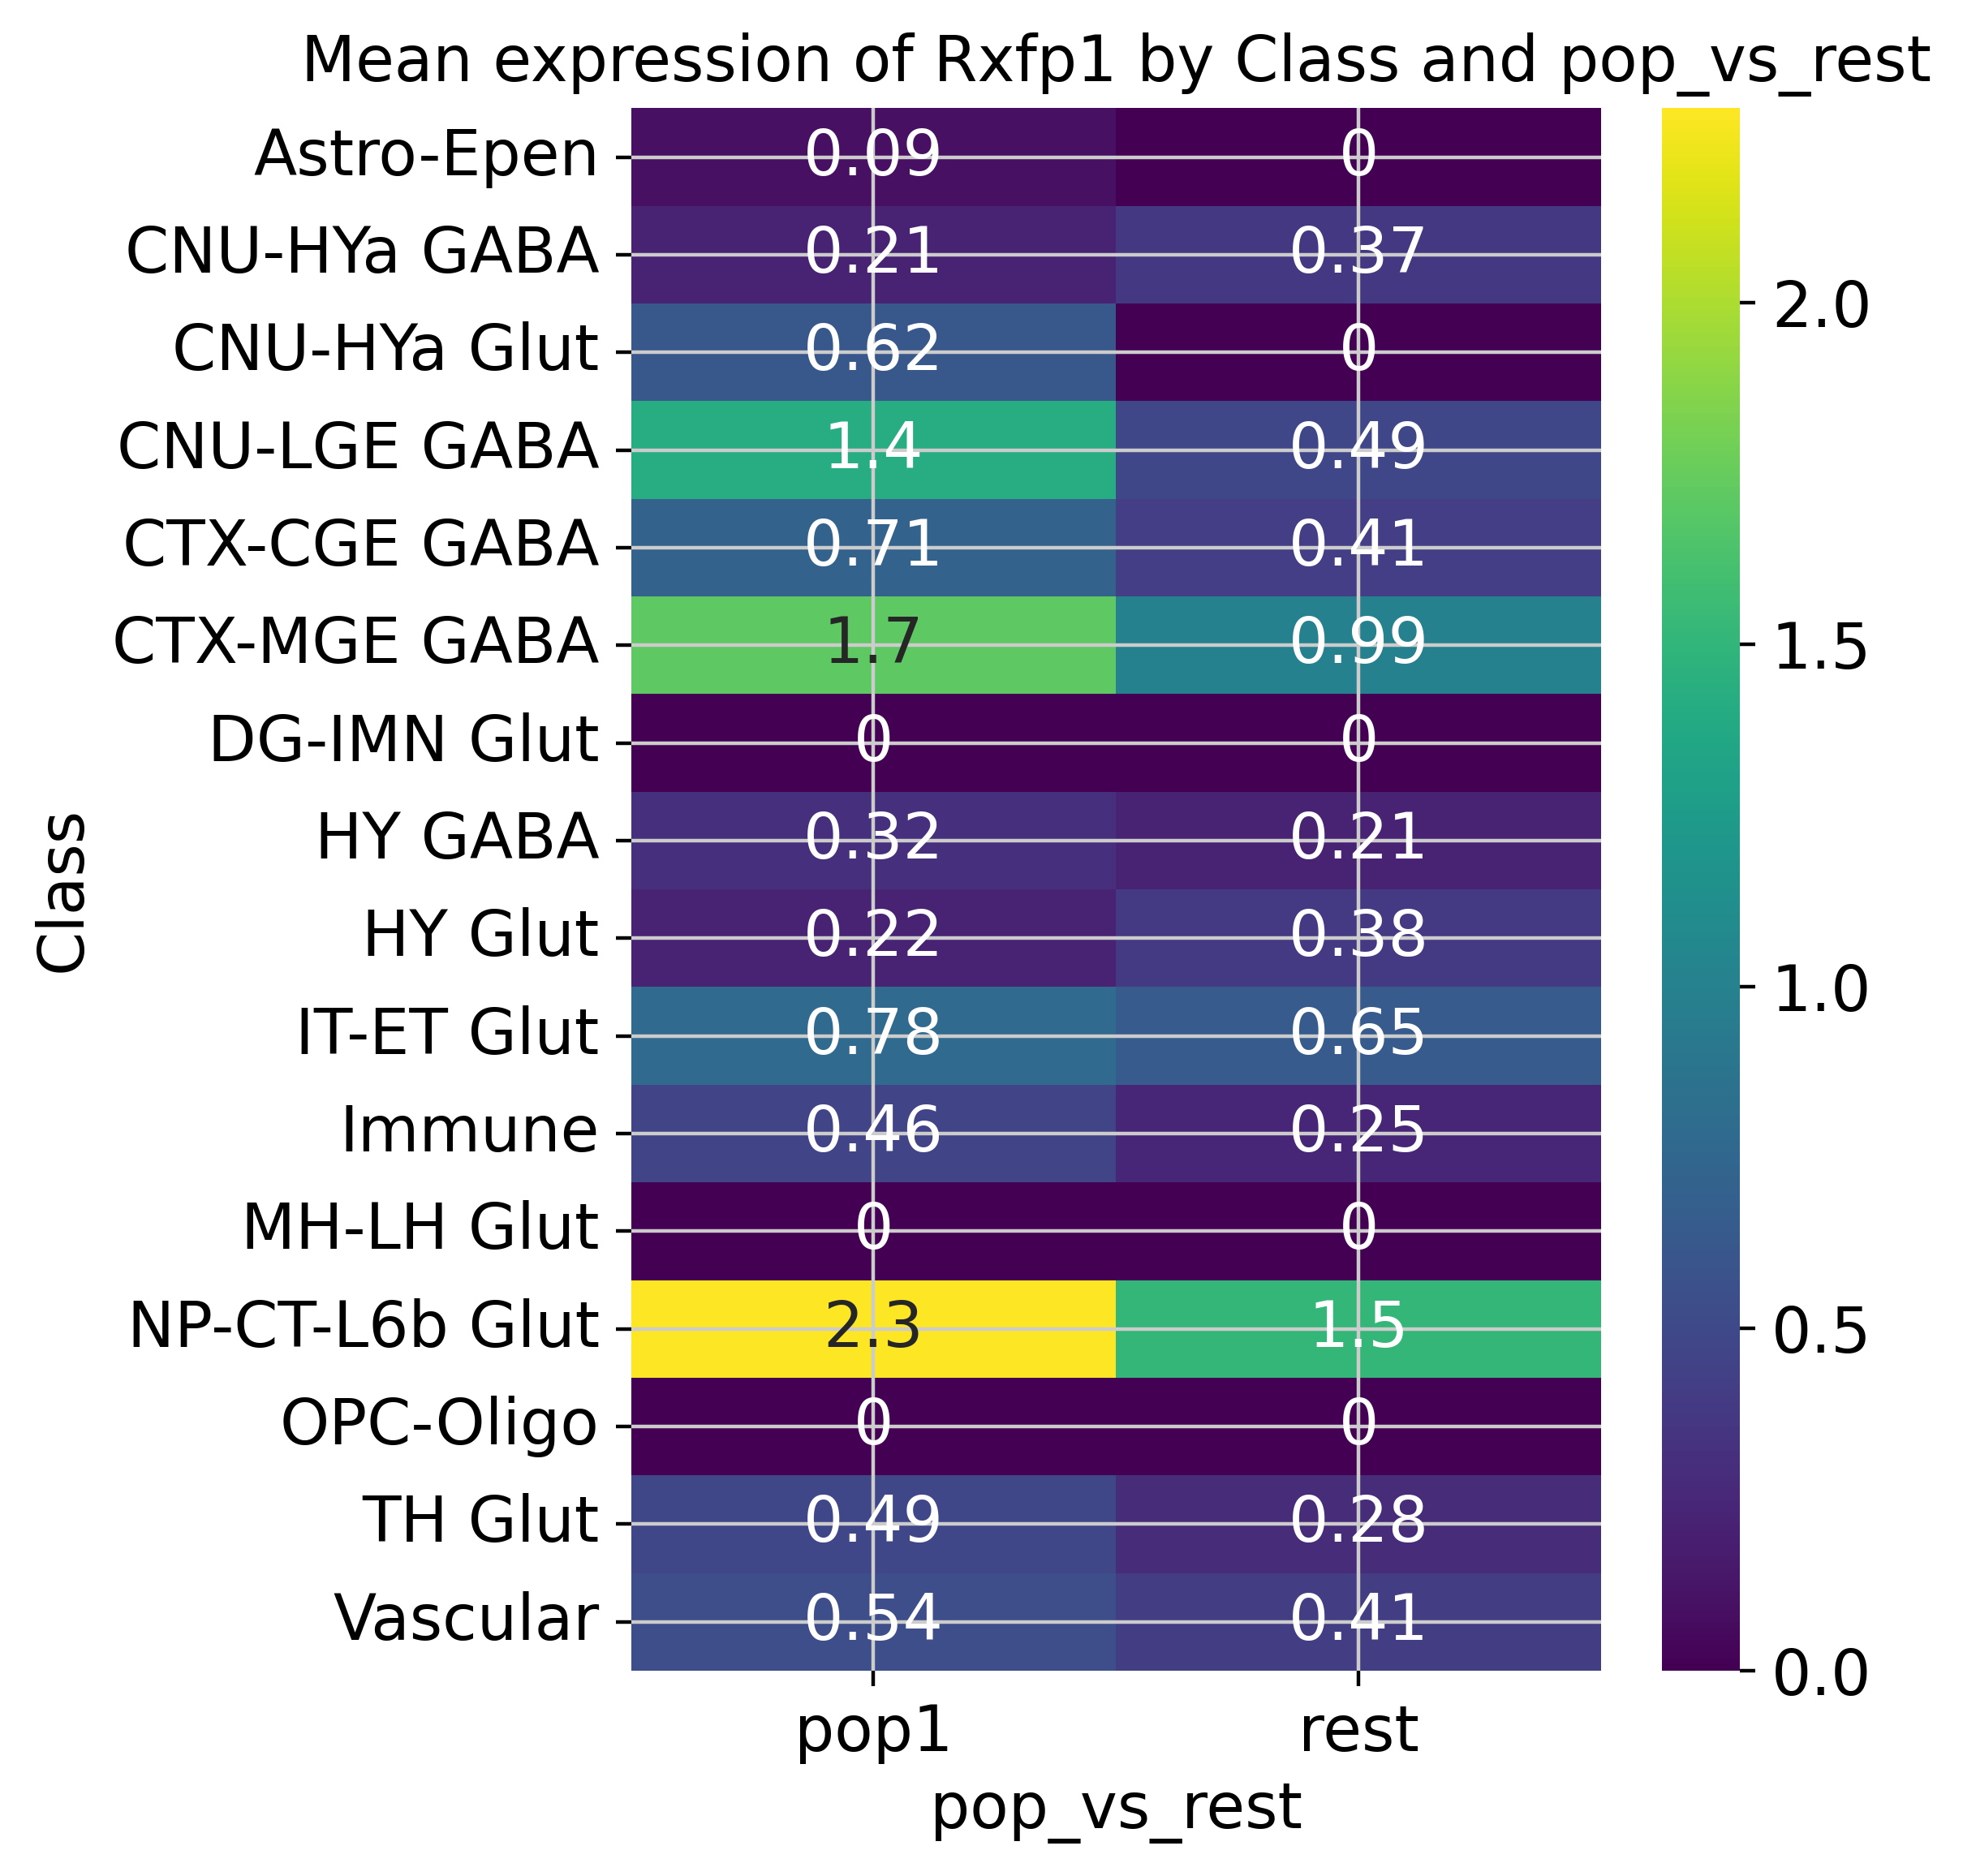

In [111]:

gene = "Rxfp1"  # your gene name here

# Extract expression for this gene (as Series)
expr = combined.to_df()[gene]

# Metadata
meta = combined.obs.copy()
meta["Class_str"] = meta["Class"].astype(str)
meta["poprest_str"] = meta["pop_vs_rest"].astype(str)

# Combine expression and metadata into one DataFrame
df = pd.DataFrame({
    "expression": expr.values,
    "Class": meta["Class_str"].values,
    "pop_vs_rest": meta["poprest_str"].values
})

# Group by Class and pop_vs_rest and calculate mean expression
heatmap_data = df.groupby(["Class", "pop_vs_rest"])["expression"].mean().unstack()

# Plot heatmap (rows=Class, columns=pop_vs_rest)
plt.figure(figsize=(6, max(6, 0.3*len(heatmap_data))))
sns.heatmap(heatmap_data, annot=True, cmap="viridis")
plt.title(f"Mean expression of {gene} by Class and pop_vs_rest")
plt.xlabel("pop_vs_rest")
plt.ylabel("Class")
plt.tight_layout()
plt.show()



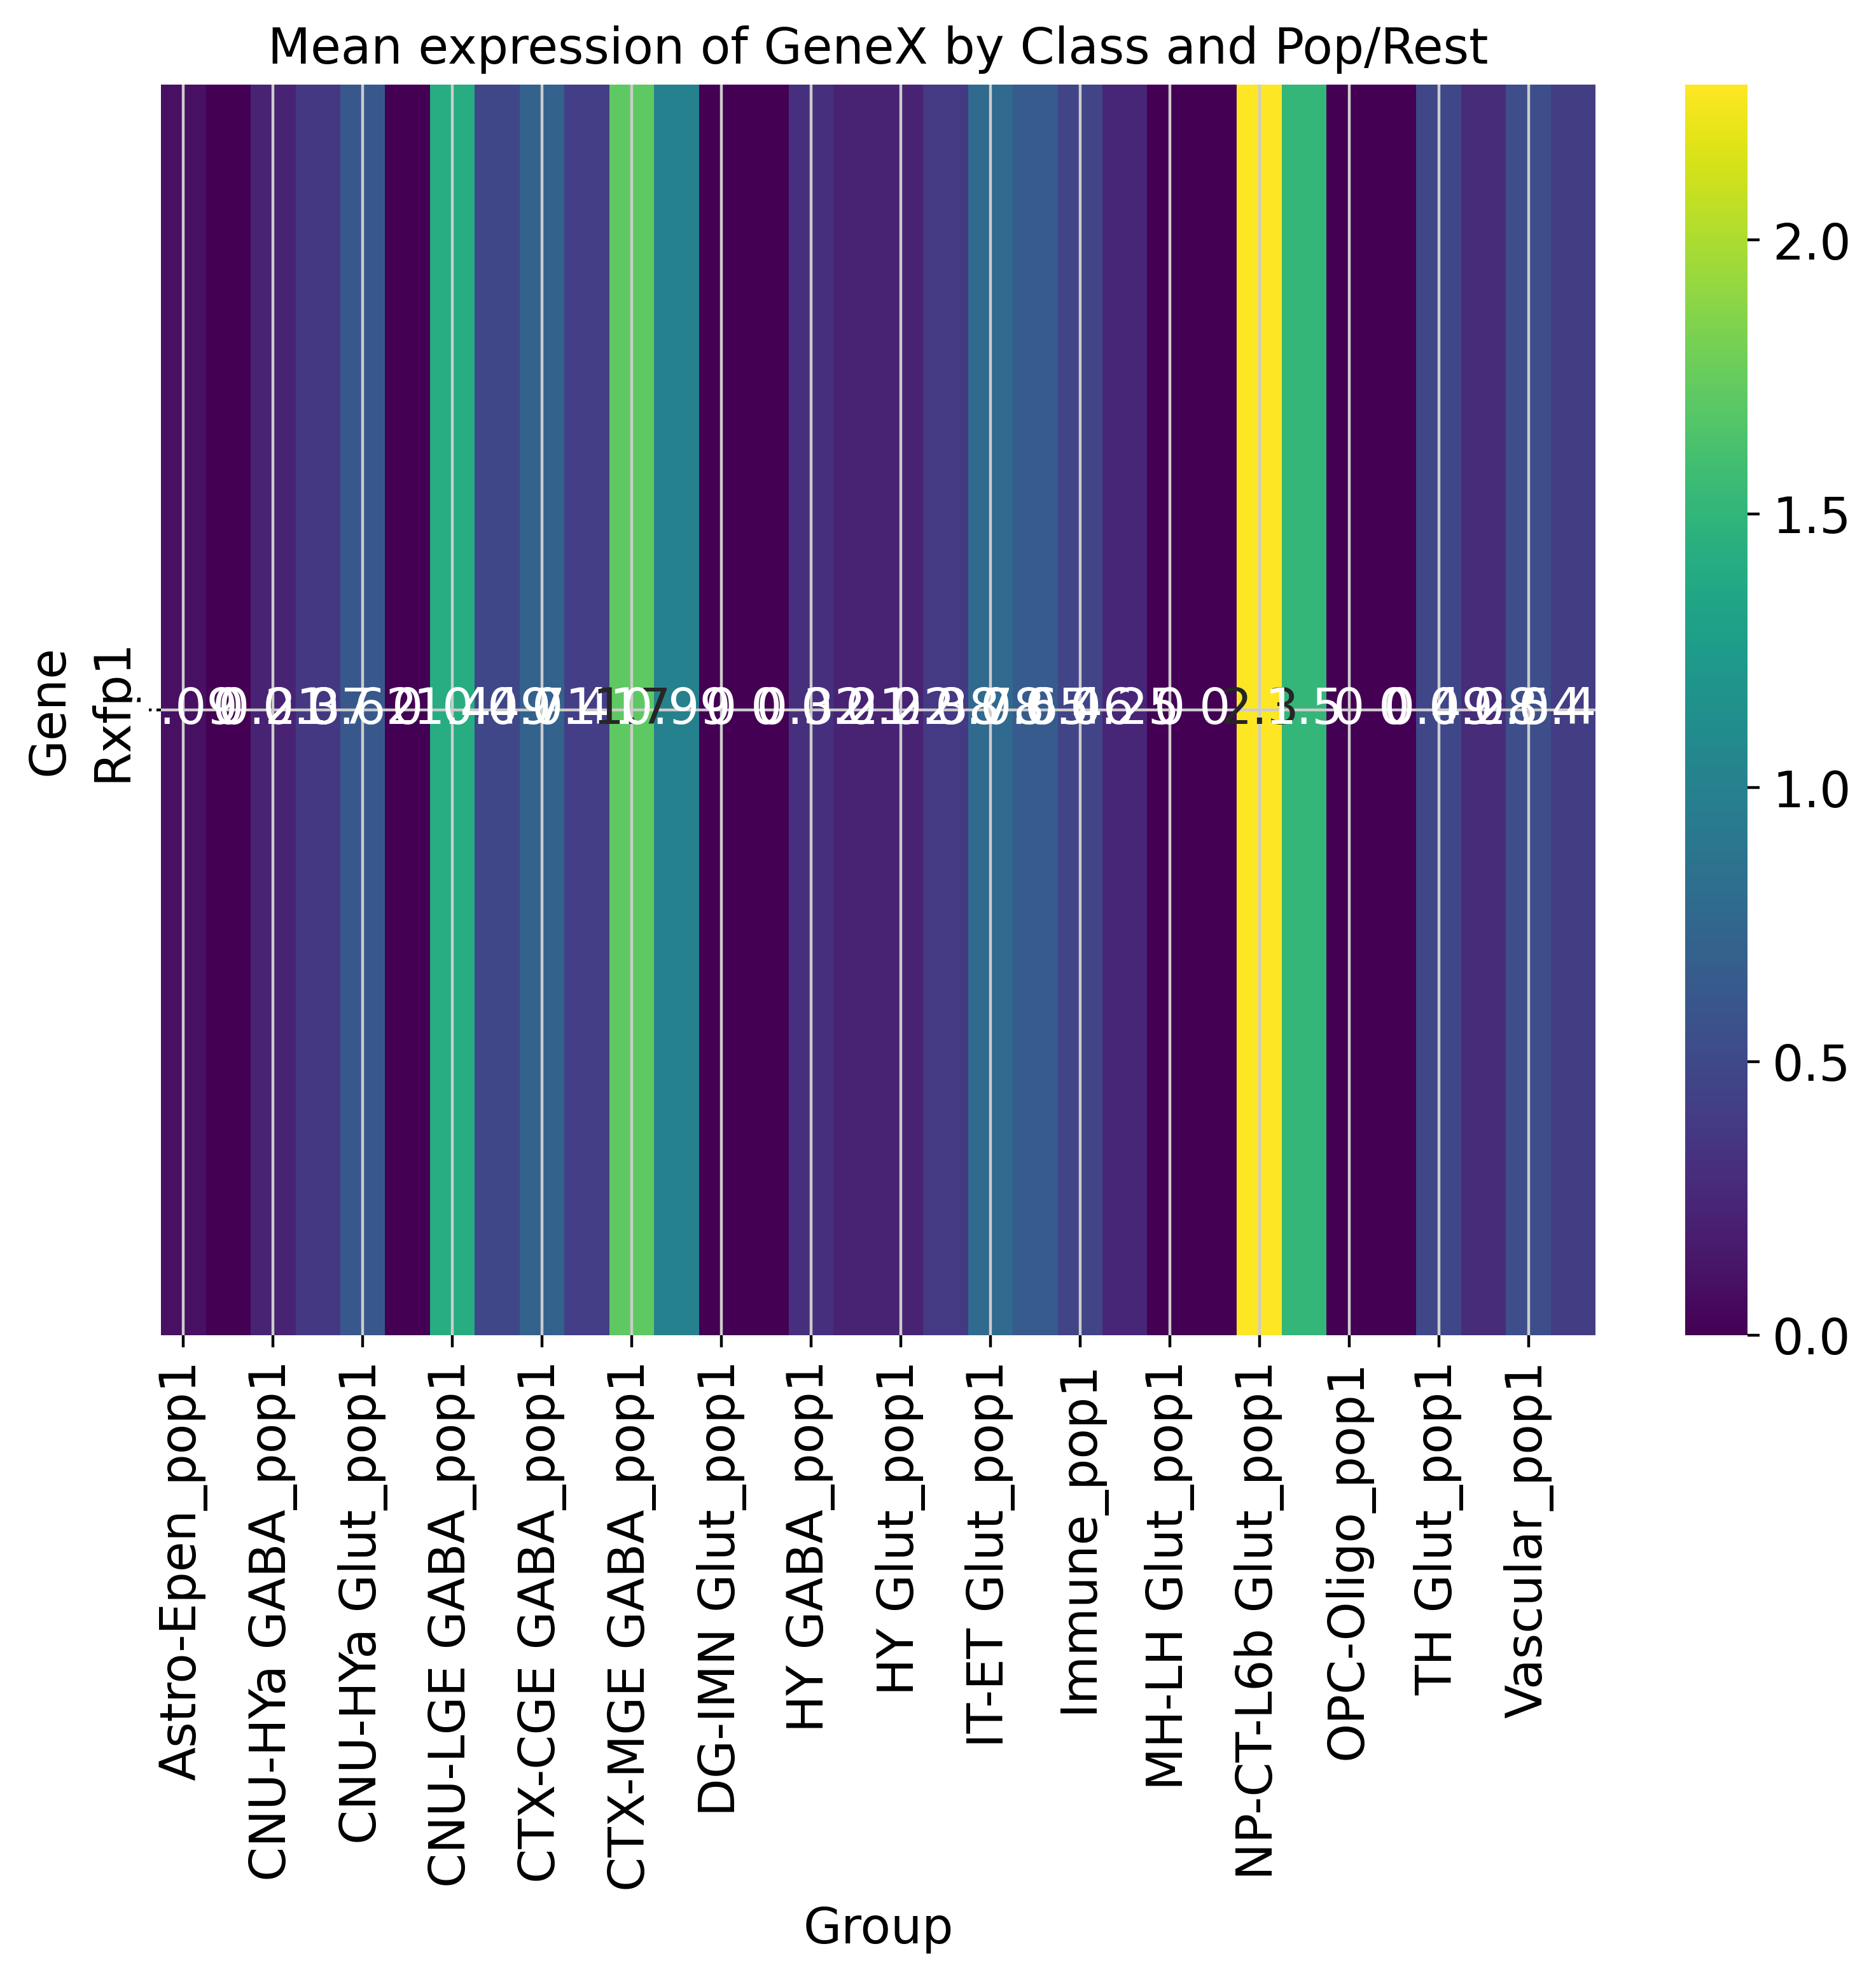

In [103]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(heatmap_data, cmap="viridis", annot=True)
plt.title("Mean expression of GeneX by Class and Pop/Rest")
plt.xlabel("Group")
plt.ylabel("Gene")
plt.tight_layout()
plt.show()

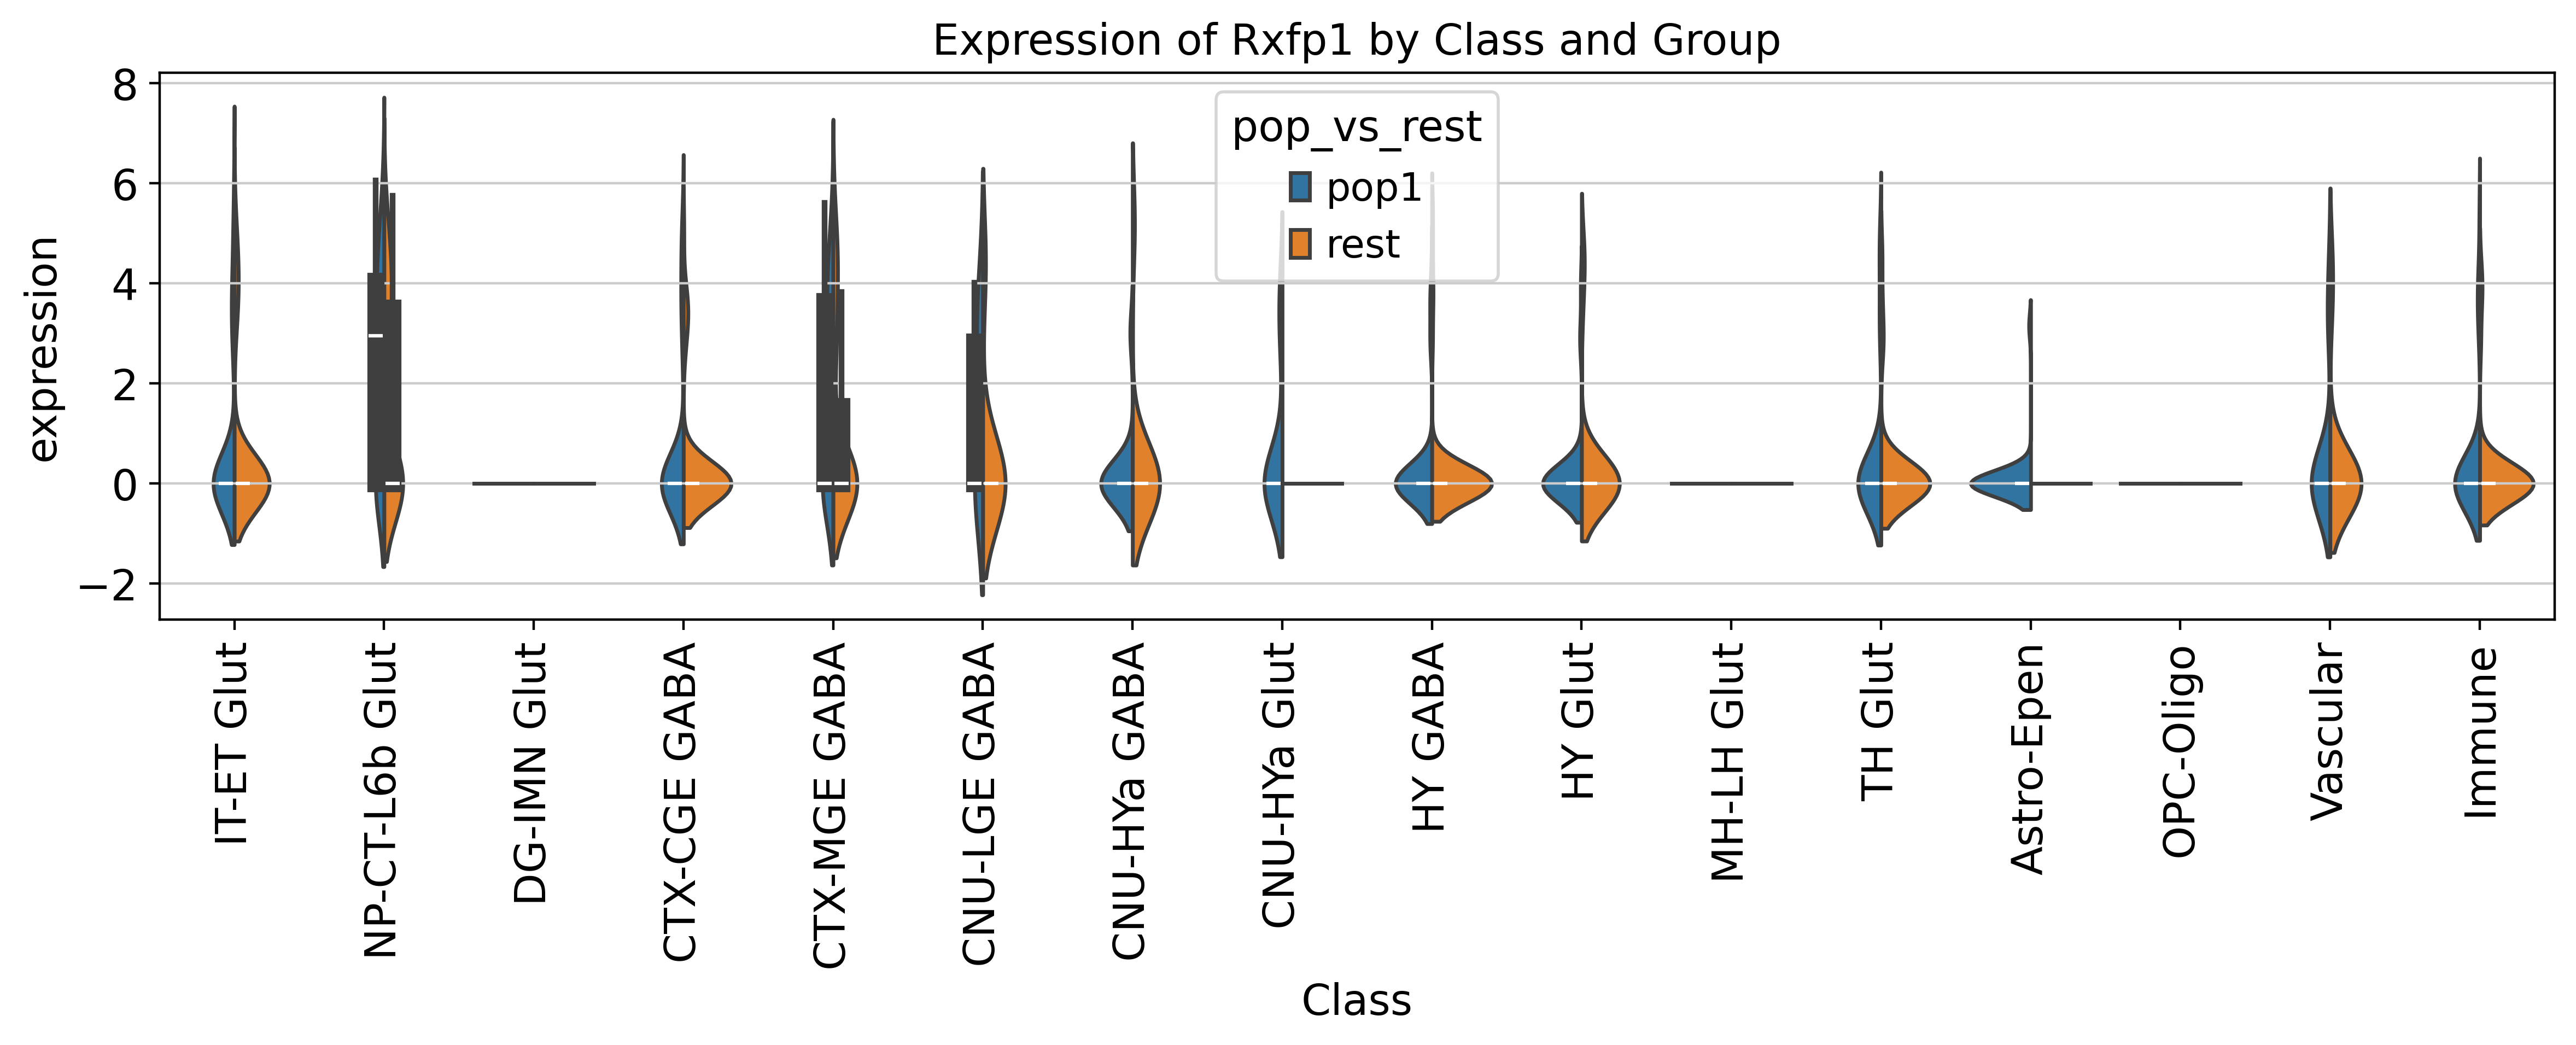

In [76]:
plt.figure(figsize=(12, 5))
sns.violinplot(
    data=df,
    x="Class",
    y="expression",
    hue="pop_vs_rest",
    split=True,
    inner="box"  # Removes boxplot
)
plt.xticks(rotation=90)
plt.title(f"Expression of {gene} by Class and Group")
plt.tight_layout()
plt.show()

In [43]:
summary_df[summary_df["Avg_PValue"]<0.05][summary_df[summary_df["Gene"]=="DystrophinExon51_53"],]

InvalidIndexError: (                   Gene  Avg_LogFC  Avg_PValue  Significance_Count
87  DystrophinExon51_53   0.549768    0.614965                   0,)

In [34]:
summary_df[summary_df["Avg_PValue"]<0.05].sort_values(by='Avg_LogFC',ascending=True).head(40)

,Gene,Avg_LogFC,Avg_PValue,Significance_Count
157,Mal,-1.300967,0.003210,829
160,Mbp,-0.321635,0.040972,721
158,Map2,0.431616,0.002163,835
218,Ptprd,0.608364,0.034381,687
71,Deptor,0.618161,0.021448,738
83,Dpy19l1,0.631503,0.023765,737
137,Id2,0.633798,0.048910,679
29,Cbln1,0.704502,0.024194,736
203,Pip5k1b,0.716344,0.016249,770
296,Zfpm2,0.723827,0.030701,691


In [38]:
summary_df.sort_values(by='Avg_LogFC',ascending=True).head(70)

,Gene,Avg_LogFC,Avg_PValue,Significance_Count
157,Mal,-1.300967,0.003210,829
187,Opalin,-1.176506,0.147936,383
164,Mog,-1.085126,0.243092,366
213,Prox1,-1.080465,0.283524,419
7,Aldh1a2,-1.022500,0.452855,322
...,...,...,...,...
262,Sox2,-0.153308,0.305988,358
111,Foxp2,-0.149254,0.242513,315
85,DystrophinExon50_51,-0.144062,0.871322,0
41,Cdh20,-0.121564,0.306038,356


In [96]:
sig_jaccard_df 

,Iteration,Jaccard_Significant
0,20,0.513889
1,30,0.506667
2,40,0.513889
3,50,0.492063
4,60,0.469697
5,70,0.473684
6,80,0.545455
7,90,0.394366


In [ ]:
import numpy as np
import scanpy as sc
from tqdm import tqdm

# Define the population masks
pop1_mask = adata.obs['Skipping_Positive'] == 'Positive'
pop1 = adata[pop1_mask]
rest = adata[~pop1_mask]

# Count cells by Class and Region
joint_counts = pop1.obs.groupby(['Class', 'Region']).size()
used_cells = set()

# Parameters
n_permutations = 1000
gene_names = adata.var_names
pval_threshold = 0.05

# Storage for results
gene_pvals = {gene: [] for gene in gene_names}
gene_logfc = {gene: [] for gene in gene_names}
gene_sig_counts = {gene: 0 for gene in gene_names}

# Permutation loop
for i in tqdm(range(n_permutations), desc="Permutations"):
    print(f"\nPermutation {i+1}")
    sampled_indices = []
    ##available_rest = rest[~rest.obs_names.isin(used_cells)]
    ##print(len(available_rest))
    skip_permutation = False

    for (ct, rg), count in joint_counts.items():
        pool_exact = available_rest.obs[
            (available_rest.obs['Class'] == ct) &
            (available_rest.obs['Region'] == rg)
        ]
        

        if len(pool_exact) >= count:
            sampled = np.random.choice(pool_exact.index.to_numpy(), size=count, replace=False)
        else:
            pool_ct = available_rest.obs[available_rest.obs['Class'] == ct]
            if len(pool_ct) >= count:
                sampled = np.random.choice(pool_ct.index.to_numpy(), size=count, replace=False)
            else:
                pool_rg = available_rest.obs[available_rest.obs['Region'] == rg]
                if len(pool_rg) >= count:
                    sampled = np.random.choice(pool_rg.index.to_numpy(), size=count, replace=False)
                else:
                    print(f"Not enough cells for Class={ct}, Region={rg}")
                    skip_permutation = True
                    break

        sampled_indices.extend(sampled)

    if skip_permutation:
        continue

    if len(sampled_indices) != pop1.n_obs:
        print("Sample size mismatch, skipping permutation.")
        continue

    if len(set(sampled_indices) & set(pop1.obs_names)) > 0:
        print("Overlap with pop1 detected, skipping permutation.")
        continue

    ##used_cells.update(sampled_indices)
    rest_sampled = rest[sampled_indices].copy()
    combined_adata = pop1.concatenate(rest_sampled, batch_key=None)
    combined_adata.obs['pop_vs_rest'] = ['pop1'] * pop1.shape[0] + ['rest'] * rest_sampled.shape[0]

    sc.tl.rank_genes_groups(
        combined_adata,
        groupby='pop_vs_rest',
        groups=['pop1'],
        reference='rest',
        method='wilcoxon',
        n_genes=combined_adata.shape[1],
        use_raw=False
    )

    result_df = sc.get.rank_genes_groups_df(combined_adata, group='pop1')

    for _, row in result_df.iterrows():
        gene = row['names']
        fc = row['logfoldchanges']
        p = row['pvals']

        gene_logfc[gene].append(fc)
        gene_pvals[gene].append(p)

        if p < pval_threshold:
            gene_sig_counts[gene] += 1

print("\nFinished all permutations.")


# Summarize results
summary_data = []

for gene in gene_logfc:
    avg_logfc = np.mean(gene_logfc[gene]) if gene_logfc[gene] else np.nan
    avg_pval = np.mean(gene_pvals[gene]) if gene_pvals[gene] else np.nan
    sig_count = gene_sig_counts.get(gene, 0)
    summary_data.append((gene, avg_logfc, avg_pval, sig_count))

# Create DataFrame
summary_df = pd.DataFrame(summary_data, columns=['Gene', 'Avg_LogFC', 'Avg_PValue', 'Significance_Count'])

# Sort by significance count descending

summary_df_sorted = summary_df.sort_values(by='Significance_Count', ascending=False)


# Display top results
print("\nTop genes by significance count:")



In [38]:
import numpy as np
import scanpy as sc
from tqdm import tqdm

# Define the population masks
pop1_mask = adata.obs['Skipping_Positive'] == 'Positive'
pop1 = adata[pop1_mask]
rest = adata[~pop1_mask]

# Count cells by Class and Region
joint_counts = pop1.obs.groupby(['Class', 'Region']).size()
used_cells = set()

# Parameters
n_permutations = 100
gene_names = adata.var_names
pval_threshold = 0.05

# Storage for results
gene_pvals = {gene: [] for gene in gene_names}
gene_logfc = {gene: [] for gene in gene_names}
gene_sig_counts = {gene: 0 for gene in gene_names}

# Permutation loop
for i in tqdm(range(n_permutations), desc="Permutations"):
    print(f"\nPermutation {i+1}")
    sampled_indices = []
    available_rest = rest[~rest.obs_names.isin(used_cells)]
    print(len(available_rest))
    skip_permutation = False

    for (ct, rg), count in joint_counts.items():
        pool_exact = available_rest.obs[
            (available_rest.obs['Class'] == ct) &
            (available_rest.obs['Region'] == rg)
        ]
        

        if len(pool_exact) >= count:
            sampled = np.random.choice(pool_exact.index.to_numpy(), size=count, replace=False)
        else:
            pool_ct = available_rest.obs[available_rest.obs['Class'] == ct]
            if len(pool_ct) >= count:
                sampled = np.random.choice(pool_ct.index.to_numpy(), size=count, replace=False)
            else:
                pool_rg = available_rest.obs[available_rest.obs['Region'] == rg]
                if len(pool_rg) >= count:
                    sampled = np.random.choice(pool_rg.index.to_numpy(), size=count, replace=False)
                else:
                    print(f"Not enough cells for Class={ct}, Region={rg}")
                    skip_permutation = True
                    break

        sampled_indices.extend(sampled)

    if skip_permutation:
        continue

    if len(sampled_indices) != pop1.n_obs:
        print("Sample size mismatch, skipping permutation.")
        continue

    if len(set(sampled_indices) & set(pop1.obs_names)) > 0:
        print("Overlap with pop1 detected, skipping permutation.")
        continue

    used_cells.update(sampled_indices)
    rest_sampled = rest[sampled_indices].copy()
    combined_adata = pop1.concatenate(rest_sampled, batch_key=None)
    combined_adata.obs['pop_vs_rest'] = ['pop1'] * pop1.shape[0] + ['rest'] * rest_sampled.shape[0]

    sc.tl.rank_genes_groups(
        combined_adata,
        groupby='pop_vs_rest',
        groups=['pop1'],
        reference='rest',
        method='wilcoxon',
        n_genes=combined_adata.shape[1],
        use_raw=False
    )

    result_df = sc.get.rank_genes_groups_df(combined_adata, group='pop1')

    for _, row in result_df.iterrows():
        gene = row['names']
        fc = row['logfoldchanges']
        p = row['pvals']

        gene_logfc[gene].append(fc)
        gene_pvals[gene].append(p)

        if p < pval_threshold:
            gene_sig_counts[gene] += 1

print("\nFinished all permutations.")


# Summarize results
summary_data = []

for gene in gene_logfc:
    avg_logfc = np.mean(gene_logfc[gene]) if gene_logfc[gene] else np.nan
    avg_pval = np.mean(gene_pvals[gene]) if gene_pvals[gene] else np.nan
    sig_count = gene_sig_counts.get(gene, 0)
    summary_data.append((gene, avg_logfc, avg_pval, sig_count))

# Create DataFrame
summary_df = pd.DataFrame(summary_data, columns=['Gene', 'Avg_LogFC', 'Avg_PValue', 'Significance_Count'])

# Sort by significance count descending

summary_df_sorted = summary_df.sort_values(by='Avg_LogFC', ascending=False)


# Display top results
print("\nTop genes by significance count:")
print(summary_df_sorted.head(10))




/tmp/ipykernel_1834245/2965909070.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  joint_counts = pop1.obs.groupby(['Class', 'Region']).size()
Permutations:   0%|          | 0/100 [00:00<?, ?it/s]


Permutation 1
229643


/tmp/ipykernel_1834245/2965909070.py:69: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  combined_adata = pop1.concatenate(rest_sampled, batch_key=None)
Permutations:   1%|          | 1/100 [00:05<08:27,  5.13s/it]


Permutation 2
228832


/tmp/ipykernel_1834245/2965909070.py:69: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  combined_adata = pop1.concatenate(rest_sampled, batch_key=None)
Permutations:   2%|▏         | 2/100 [00:10<08:17,  5.08s/it]


Permutation 3
228021


... (192 outputs left out)

/tmp/ipykernel_1834245/2965909070.py:69: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  combined_adata = pop1.concatenate(rest_sampled, batch_key=None)
Permutations:  99%|█████████▉| 99/100 [07:05<00:03,  3.61s/it]


Permutation 100
149358


/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_1834245/2965909070.py:69: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  combined_adata = pop1.concatenate(rest_sampled, batch_key=None)
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are


Finished all permutations.

Top genes by significance count:
                     Gene  Avg_LogFC     Avg_PValue  Significance_Count
86    DystrophinExon50_53  34.430511  2.303047e-266                 100
75                  Dp140   8.396795   9.722233e-01                   0
74                  Dp116   1.645491   8.945360e-01                   0
91   Dystrophin_Exon56_62   1.098303   6.140712e-05                 100
76                  Dp260   0.866312   4.988047e-01                   0
89   Dystrophin_Exon30_44   0.827906   5.347533e-05                 100
119                  Gfap   0.758371   1.291106e-03                 100
194                Pde11a   0.753027   1.255528e-01                  16
235                 Rxfp1   0.746155   2.574020e-02                  87
191                 Parm1   0.744895   3.392568e-04                 100


In [42]:
summary_df_sorted.head(30)

,Gene,Avg_LogFC,Avg_PValue,Significance_Count
86,DystrophinExon50_53,34.430511,2.303047e-266,100
75,Dp140,8.396795,9.722233e-01,0
74,Dp116,1.645491,8.945360e-01,0
91,Dystrophin_Exon56_62,1.098303,6.140712e-05,100
76,Dp260,0.866312,4.988047e-01,0
89,Dystrophin_Exon30_44,0.827906,5.347533e-05,100
119,Gfap,0.758371,1.291106e-03,100
194,Pde11a,0.753027,1.255528e-01,16
235,Rxfp1,0.746155,2.574020e-02,87
191,Parm1,0.744895,3.392568e-04,100


In [37]:
count

2

In [35]:
    for (ct, rg), count in joint_counts.items():
        pool_exact = available_rest.obs[
            (available_rest.obs['Class'] == ct) &
            (available_rest.obs['Region'] == rg)
        ]

In [36]:
pool_exact

,cell_id,transcript_counts,control_probe_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,region,...,Slide,Sample,Run,technique,Group,Region,Class,Region_hlevel,batch,Skipping_Positive
5736-0,aecadige-1,90,0,0,0,1,91,218.465945,7.315313,cell_circles,...,1,886,1,Xenium,tcDNA,Ventricular system,Immune,Ventricular system,0,Negative
5738-0,aecakicf-1,83,0,0,0,1,84,48.001095,13.050157,cell_circles,...,1,886,1,Xenium,tcDNA,Ventricular system,Immune,Ventricular system,0,Negative
66896-0,cpekalfb-1,244,0,0,0,3,247,314.106886,6.908907,cell_circles,...,1,886,1,Xenium,tcDNA,Ventricular system,Immune,Ventricular system,0,Negative
160038-0,hbeeheej-1,712,0,1,1,38,752,482.675174,82.816566,cell_circles,...,1,886,1,Xenium,tcDNA,Ventricular system,Immune,Ventricular system,0,Negative
184270-0,icfphkmi-1,837,0,0,1,39,877,684.884869,131.178911,cell_circles,...,1,886,1,Xenium,tcDNA,Ventricular system,Immune,Ventricular system,0,Negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
290357-2,mmokfife-1,85,0,0,0,7,92,60.148127,9.392500,cell_circles,...,3,891,2,Xenium,tcDNA,Ventricular system,Immune,Ventricular system,2,Negative
305797-2,nhkdgpni-1,82,0,0,0,3,85,53.645627,7.134688,cell_circles,...,3,891,2,Xenium,tcDNA,Ventricular system,Immune,Ventricular system,2,Negative
317263-2,npoigfck-1,617,0,0,0,22,639,659.868305,56.851721,cell_circles,...,3,891,2,Xenium,tcDNA,Ventricular system,Immune,Ventricular system,2,Negative
317427-2,oaadmmag-1,316,2,0,0,18,336,294.057511,49.039689,cell_circles,...,3,891,2,Xenium,tcDNA,Ventricular system,Immune,Ventricular system,2,Negative


In [24]:
summary_df_sorted[summary_df_sorted["Significance_Count"]>0]

,Gene,Avg_LogFC,Avg_PValue,Significance_Count
191,Parm1,0.726700,0.000611,10
91,Dystrophin_Exon56_62,1.060723,0.000049,10
88,Dystrophin_Exon2_29,0.695347,0.000379,10
61,Cpne6,0.426510,0.016004,10
89,Dystrophin_Exon30_44,0.843518,0.000009,10
...,...,...,...,...
194,Pde11a,0.718883,0.138890,1
72,Dkk3,0.256028,0.125166,1
80,Dp427p,0.526534,0.193532,1
50,Clmn,0.266118,0.367889,1


In [25]:
summary_df.sort_values(by='Avg_LogFC', ascending=False)

,Gene,Avg_LogFC,Avg_PValue,Significance_Count
86,DystrophinExon50_53,34.430511,2.303047e-266,10
75,Dp140,10.456699,9.623194e-01,0
74,Dp116,1.333717,8.705233e-01,0
91,Dystrophin_Exon56_62,1.060723,4.934027e-05,10
76,Dp260,0.869806,4.901486e-01,0
...,...,...,...,...
122,Gjc3,-0.407133,6.137997e-02,7
283,Trbc2,-0.409165,6.808720e-01,0
187,Opalin,-0.456254,3.393026e-01,2
11,Arc,-0.520335,7.008895e-03,10


In [93]:
len(sampled_indices)

14

In [91]:
sampled

array([], dtype=object)

In [92]:
gene_logfc

{'2010300C02Rik': [],
 'Acsbg1': [],
 'Acta2': [],
 'Acvrl1': [],
 'Adamts2': [],
 'Adamtsl1': [],
 'Adgrl4': [],
 'Aldh1a2': [],
 'Angpt1': [],
 'Ano1': [],
 'Aqp4': [],
 'Arc': [],
 'Arhgap12': [],
 'Arhgap25': [],
 'Arhgap6': [],
 'Arhgef28': [],
 'Arpp21': [],
 'Bcl11b': [],
 'Bdnf': [],
 'Bhlhe22': [],
 'Bhlhe40': [],
 'Bmp4': [],
 'Btbd11': [],
 'Cabp7': [],
 'Cacna2d2': [],
 'Calb1': [],
 'Calb2': [],
 'Car4': [],
 'Carmn': [],
 'Cbln1': [],
 'Cbln4': [],
 'Ccdc153': [],
 'Ccn2': [],
 'Cd24a': [],
 'Cd300c2': [],
 'Cd44': [],
 'Cd53': [],
 'Cd68': [],
 'Cd74': [],
 'Cd93': [],
 'Cdh13': [],
 'Cdh20': [],
 'Cdh4': [],
 'Cdh6': [],
 'Cdh9': [],
 'Celf2': [],
 'Chat': [],
 'Chodl': [],
 'Chrm2': [],
 'Cldn5': [],
 'Clmn': [],
 'Cntn6': [],
 'Cntnap4': [],
 'Cntnap5b': [],
 'Cobll1': [],
 'Col19a1': [],
 'Col1a1': [],
 'Col6a1': [],
 'Cort': [],
 'Cplx3': [],
 'Cpne4': [],
 'Cpne6': [],
 'Cpne8': [],
 'Crh': [],
 'Cspg4': [],
 'Cux2': [],
 'Cwh43': [],
 'Cyp1b1': [],
 'Dab1': [],
 '

In [72]:
gene_logfc.setdefault(gene, []).append(fc)
gene_pvals.setdefault(gene, []).append(p)

In [76]:
gene_logfc

{'2010300C02Rik': [],
 'Acsbg1': [],
 'Acta2': [],
 'Acvrl1': [],
 'Adamts2': [],
 'Adamtsl1': [],
 'Adgrl4': [],
 'Aldh1a2': [],
 'Angpt1': [],
 'Ano1': [],
 'Aqp4': [],
 'Arc': [],
 'Arhgap12': [],
 'Arhgap25': [],
 'Arhgap6': [],
 'Arhgef28': [],
 'Arpp21': [],
 'Bcl11b': [],
 'Bdnf': [],
 'Bhlhe22': [],
 'Bhlhe40': [],
 'Bmp4': [],
 'Btbd11': [],
 'Cabp7': [],
 'Cacna2d2': [],
 'Calb1': [],
 'Calb2': [],
 'Car4': [],
 'Carmn': [],
 'Cbln1': [],
 'Cbln4': [],
 'Ccdc153': [],
 'Ccn2': [],
 'Cd24a': [],
 'Cd300c2': [],
 'Cd44': [],
 'Cd53': [],
 'Cd68': [],
 'Cd74': [],
 'Cd93': [],
 'Cdh13': [],
 'Cdh20': [],
 'Cdh4': [],
 'Cdh6': [],
 'Cdh9': [],
 'Celf2': [],
 'Chat': [],
 'Chodl': [],
 'Chrm2': [],
 'Cldn5': [],
 'Clmn': [],
 'Cntn6': [],
 'Cntnap4': [],
 'Cntnap5b': [],
 'Cobll1': [],
 'Col19a1': [],
 'Col1a1': [],
 'Col6a1': [],
 'Cort': [],
 'Cplx3': [],
 'Cpne4': [],
 'Cpne6': [],
 'Cpne8': [],
 'Crh': [],
 'Cspg4': [],
 'Cux2': [],
 'Cwh43': [],
 'Cyp1b1': [],
 'Dab1': [],
 '

In [69]:
logfc_map

{'DystrophinExon50_53': 34.43051,
 'Dystrophin_Exon79': 0.8384299,
 'Dystrophin_Exon30_44': 0.8637,
 'Dystrophin_Exon2_29': 0.86754197,
 'Dystrophin_Exon45_49': 0.76357615,
 'Spp1': 0.8810198,
 'Dp427c': 0.7840145,
 'Dystrophin_Exon56_62': 0.89112794,
 'Gfap': 0.7376564,
 'Ndst3': 0.6374096,
 'Parm1': 0.62941337,
 'Plcxd3': 0.6837918,
 'Cntnap4': 0.6635123,
 'Celf2': 0.3221273,
 'Cpne8': 0.528081,
 'Sema3e': 0.7206046,
 'Sox11': 0.58603656,
 'Rnf152': 0.6162258,
 'Rspo2': 0.8068847,
 'Rxfp1': 0.895674,
 'Cpne4': 0.51488525,
 'Dcx': 0.57106894,
 'Lamp5': 0.5654117,
 'Galnt14': 0.5525287,
 'Fhod3': 0.37824783,
 'Nwd2': 0.52697736,
 'Pcsk5': 0.58539814,
 'Angpt1': 0.55550194,
 'Ptprd': 0.5328313,
 'Nts': 1.0992391,
 'Nrp2': 0.4763544,
 'Trem2': 0.48266926,
 'Bhlhe22': 0.42721587,
 'Cntn6': 0.5056505,
 'Necab2': 0.43539774,
 'Hat1': 0.44520488,
 'Prph': 0.63986444,
 'Eomes': 0.97355515,
 'Garnl3': 0.32485533,
 'Vwc2l': 0.47654608,
 'Rab3b': 0.40720415,
 'Rasgrf2': 0.38524827,
 'Mdga1': 0.4

In [68]:
gene_pvals

{'2010300C02Rik': [],
 'Acsbg1': [],
 'Acta2': [],
 'Acvrl1': [],
 'Adamts2': [],
 'Adamtsl1': [],
 'Adgrl4': [],
 'Aldh1a2': [],
 'Angpt1': [],
 'Ano1': [],
 'Aqp4': [],
 'Arc': [],
 'Arhgap12': [],
 'Arhgap25': [],
 'Arhgap6': [],
 'Arhgef28': [],
 'Arpp21': [],
 'Bcl11b': [],
 'Bdnf': [],
 'Bhlhe22': [],
 'Bhlhe40': [],
 'Bmp4': [],
 'Btbd11': [],
 'Cabp7': [],
 'Cacna2d2': [],
 'Calb1': [],
 'Calb2': [],
 'Car4': [],
 'Carmn': [],
 'Cbln1': [],
 'Cbln4': [],
 'Ccdc153': [],
 'Ccn2': [],
 'Cd24a': [],
 'Cd300c2': [],
 'Cd44': [],
 'Cd53': [],
 'Cd68': [],
 'Cd74': [],
 'Cd93': [],
 'Cdh13': [],
 'Cdh20': [],
 'Cdh4': [],
 'Cdh6': [],
 'Cdh9': [],
 'Celf2': [],
 'Chat': [],
 'Chodl': [],
 'Chrm2': [],
 'Cldn5': [],
 'Clmn': [],
 'Cntn6': [],
 'Cntnap4': [],
 'Cntnap5b': [],
 'Cobll1': [],
 'Col19a1': [],
 'Col1a1': [],
 'Col6a1': [],
 'Cort': [],
 'Cplx3': [],
 'Cpne4': [],
 'Cpne6': [],
 'Cpne8': [],
 'Crh': [],
 'Cspg4': [],
 'Cux2': [],
 'Cwh43': [],
 'Cyp1b1': [],
 'Dab1': [],
 '

In [ ]:
# Final summary
summary_df = pd.DataFrame({
    'gene': gene_names,
    'num_significant': [gene_sig_counts[g] for g in gene_names],
    'mean_logFC': [np.mean(gene_logfc[g]) for g in gene_names],
    'mean_pval': [np.mean(gene_pvals[g]) for g in gene_names]
}).set_index('gene')

# Save or display
summary_df_sorted = summary_df.sort_values(by='num_significant', ascending=False)
summary_df_sorted.head(20) 

In [65]:
gene_logfc.setdefault(gene, []).append(fc)

In [66]:
gene_logfc

{'2010300C02Rik': [],
 'Acsbg1': [],
 'Acta2': [],
 'Acvrl1': [],
 'Adamts2': [],
 'Adamtsl1': [],
 'Adgrl4': [],
 'Aldh1a2': [],
 'Angpt1': [],
 'Ano1': [],
 'Aqp4': [],
 'Arc': [],
 'Arhgap12': [],
 'Arhgap25': [],
 'Arhgap6': [],
 'Arhgef28': [],
 'Arpp21': [],
 'Bcl11b': [],
 'Bdnf': [],
 'Bhlhe22': [],
 'Bhlhe40': [],
 'Bmp4': [],
 'Btbd11': [],
 'Cabp7': [],
 'Cacna2d2': [],
 'Calb1': [],
 'Calb2': [],
 'Car4': [],
 'Carmn': [],
 'Cbln1': [],
 'Cbln4': [],
 'Ccdc153': [],
 'Ccn2': [],
 'Cd24a': [],
 'Cd300c2': [],
 'Cd44': [],
 'Cd53': [],
 'Cd68': [],
 'Cd74': [],
 'Cd93': [],
 'Cdh13': [],
 'Cdh20': [],
 'Cdh4': [],
 'Cdh6': [],
 'Cdh9': [],
 'Celf2': [],
 'Chat': [],
 'Chodl': [],
 'Chrm2': [],
 'Cldn5': [],
 'Clmn': [],
 'Cntn6': [],
 'Cntnap4': [],
 'Cntnap5b': [],
 'Cobll1': [],
 'Col19a1': [],
 'Col1a1': [],
 'Col6a1': [],
 'Cort': [],
 'Cplx3': [],
 'Cpne4': [],
 'Cpne6': [],
 'Cpne8': [],
 'Crh': [],
 'Cspg4': [],
 'Cux2': [],
 'Cwh43': [],
 'Cyp1b1': [],
 'Dab1': [],
 '

In [57]:
summary_df_sorted.head(100)

,num_significant,mean_logFC,mean_pval
gene,,,
Zfpm2,0,0,1.0
2010300C02Rik,0,0,1.0
Acsbg1,0,0,1.0
Acta2,0,0,1.0
Acvrl1,0,0,1.0
...,...,...,...
DystrophinExon51_53,0,0,1.0
Dystrophin_Exon2_29,0,0,1.0
Dner,0,0,1.0


In [56]:
gene_names

Index(['2010300C02Rik', 'Acsbg1', 'Acta2', 'Acvrl1', 'Adamts2', 'Adamtsl1',
       'Adgrl4', 'Aldh1a2', 'Angpt1', 'Ano1',
       ...
       'Ttr', 'Unc13c', 'Vat1l', 'Vcan', 'Vip', 'Vwc2l', 'Wfs1', 'Zfp366',
       'Zfp536', 'Zfpm2'],
      dtype='object', length=297)

In [55]:
logfc_map.get(gene, 0.0)

0.31334636

In [54]:
 gene_logfc

{'2010300C02Rik': [],
 'Acsbg1': [],
 'Acta2': [],
 'Acvrl1': [],
 'Adamts2': [],
 'Adamtsl1': [],
 'Adgrl4': [],
 'Aldh1a2': [],
 'Angpt1': [],
 'Ano1': [],
 'Aqp4': [],
 'Arc': [],
 'Arhgap12': [],
 'Arhgap25': [],
 'Arhgap6': [],
 'Arhgef28': [],
 'Arpp21': [],
 'Bcl11b': [],
 'Bdnf': [],
 'Bhlhe22': [],
 'Bhlhe40': [],
 'Bmp4': [],
 'Btbd11': [],
 'Cabp7': [],
 'Cacna2d2': [],
 'Calb1': [],
 'Calb2': [],
 'Car4': [],
 'Carmn': [],
 'Cbln1': [],
 'Cbln4': [],
 'Ccdc153': [],
 'Ccn2': [],
 'Cd24a': [],
 'Cd300c2': [],
 'Cd44': [],
 'Cd53': [],
 'Cd68': [],
 'Cd74': [],
 'Cd93': [],
 'Cdh13': [],
 'Cdh20': [],
 'Cdh4': [],
 'Cdh6': [],
 'Cdh9': [],
 'Celf2': [],
 'Chat': [],
 'Chodl': [],
 'Chrm2': [],
 'Cldn5': [],
 'Clmn': [],
 'Cntn6': [],
 'Cntnap4': [],
 'Cntnap5b': [],
 'Cobll1': [],
 'Col19a1': [],
 'Col1a1': [],
 'Col6a1': [],
 'Cort': [],
 'Cplx3': [],
 'Cpne4': [],
 'Cpne6': [],
 'Cpne8': [],
 'Crh': [],
 'Cspg4': [],
 'Cux2': [],
 'Cwh43': [],
 'Cyp1b1': [],
 'Dab1': [],
 '

In [52]:
summary_df

,num_significant,mean_logFC,mean_pval
gene,,,
2010300C02Rik,0,NaN,NaN
Acsbg1,0,NaN,NaN
Acta2,0,NaN,NaN
Acvrl1,0,NaN,NaN
Adamts2,0,NaN,NaN
...,...,...,...
Vwc2l,0,NaN,NaN
Wfs1,0,NaN,NaN
Zfp366,0,NaN,NaN


In [28]:
pool = available_rest.obs[
            (available_rest.obs['Class'] == ct) &
            (available_rest.obs['Region'] == rg)
        ]

In [30]:
joint_counts

Class       Region                       
IT-ET Glut  Basolateral amygdalar nucleus    5
            CA1                              5
            CA2/3                            4
            Caudoputamen                     0
            Central amygdalar nucleus        0
                                            ..
Immune      Retrosplenial cortex             0
            Thalamus 1                       0
            Thalamus 2                       1
            Unassigned                       2
            Ventricular system               2
Length: 400, dtype: int64

In [16]:
# Set a random seed for reproducibility
np.random.seed(42)

# Identify indices for each group.
# Adjust these conditions for your dataset's specific label conventions.
pos_idx = np.where(adata.obs['Skipping_Positive'] == 'Positive')[0]
neg_idx = np.where(adata.obs['Skipping_Positive'] == 'Negative')[0]

# Get the number of positive cells for downsampling
n_pos = len(pos_idx)

# Define your thresholds
pval_threshold = 0.05    # Use p-values below this threshold (adjust as needed)
lfc_threshold = 1     # Use absolute log fold change above this threshold (adjust as needed)

# Run the DE analysis multiple times
n_iterations = 1000
de_results = []

for i in range(n_iterations):
    # Downsample negatives to match the number of positives
    neg_sample = np.random.choice(neg_idx, size=n_pos, replace=False)
    selected_idx = np.concatenate([pos_idx, neg_sample])
    adata_ds = adata[selected_idx].copy()
    
    # Optionally shuffle the cell order to remove ordering effects
    shuffled_order = np.random.permutation(adata_ds.obs_names)
    adata_ds = adata_ds[shuffled_order]
    
    # Run DE analysis using the Wilcoxon test
    sc.tl.rank_genes_groups(adata_ds, groupby='Skipping_Positive', method='wilcoxon')
    
    # Append the DE result dictionary from this iteration
    de_results.append(adata_ds.uns['rank_genes_groups'])

# Now, aggregate the results for each group based on p-value and log fold change thresholds.
groups = ['Positive', 'Negative']
agg_results = {}

for group in groups:
    # Dictionary to collect log fold changes for genes that pass the thresholds
    gene_info = defaultdict(list)
    
    for res in de_results:
        # Each DE result is a dictionary containing arrays for each group.
        gene_names = res['names'][group]
        lfc_values = res['logfoldchanges'][group]
        pvals = res['pvals'][group]  # Alternatively, you can use res['pvals_adj'][group]
        
        # Create a boolean mask for genes meeting both criteria
        mask = (pvals < pval_threshold) & (lfc_values > lfc_threshold) ##(np.abs(lfc_values) > lfc_threshold)
        
        # Record genes that satisfy the filtering criteria
        for gene, lfc in zip(gene_names[mask], lfc_values[mask]):
            gene_info[gene].append(lfc)
    
    # Build an aggregated DataFrame: frequency of appearance and average log fold change per gene
    df = pd.DataFrame({
        'frequency': {gene: len(lfc_list) for gene, lfc_list in gene_info.items()},
        'mean_logfoldchange': {gene: np.mean(lfc_list) for gene, lfc_list in gene_info.items()}
    })
    
    # Sort by frequency and then mean log fold change in descending order
    df = df.sort_values(by=['frequency', 'mean_logfoldchange'], ascending=False)
    agg_results[group] = df

# Display aggregated results for each group
for group in groups:
    print(f"\nAggregated DE results for group '{group}':")
    print(agg_results[group])

/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as 


Aggregated DE results for group 'Positive':
                      frequency  mean_logfoldchange
DystrophinExon50_53        1000           34.218616
Fezf2                      1000            1.770167
Dystrophin_Exon30_44       1000            1.761819
Neurod6                    1000            1.729080
Dkk3                       1000            1.706090
Arc                        1000            1.677438
Dystrophin_Exon56_62       1000            1.649670
Hs3st2                     1000            1.642571
Slc17a7                    1000            1.628130
Satb2                      1000            1.621699
Fhod3                      1000            1.585978
Dystrophin_Exon2_29        1000            1.540262
Dp427c                     1000            1.536567
Tmem132d                   1000            1.520324
Dystrophin_Exon45_49       1000            1.494994
Gm19410                    1000            1.481588
Garnl3                     1000            1.476991
2010300C02Rik      

In [12]:
pd.set_option('display.max_rows', None)

In [13]:
agg_results["Positive"]

,frequency,mean_logfoldchange
DystrophinExon50_53,1000,34.430508
Dystrophin_Exon56_62,996,1.414412
Dystrophin_Exon30_44,994,1.333882
Rxfp1,990,1.425138
Nxph3,973,1.284815
Cntnap4,968,1.229181
Dystrophin_Exon2_29,850,1.156241
Plcxd3,830,1.157648
Fezf2,805,1.171642
Ndst3,752,1.138933


In [14]:
agg_results["Negative"]

,frequency,mean_logfoldchange
Opalin,371,1.108004
Mog,146,1.064153
Gjc3,88,1.047194
Sox10,22,1.040359
Eya4,7,1.046528
Mal,3,1.051973
Enpp6,2,1.009835


In [17]:
adata = Sample_4.concatenate(Sample_5, Sample_3)

/tmp/ipykernel_3970957/821040457.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = Sample_4.concatenate(Sample_5, Sample_3)


In [18]:
sc.pp.normalize_total(adata, target_sum=1e4)  # Normalize per cell
sc.pp.log1p(adata)  # Log transformation (natural log)

In [19]:
# Define threshold (typically 0, but adjust if needed)
gene = "DystrophinExon50_53"
threshold = 0  # Can be adjusted based on data distribution

# Identify positive and negative groups
adata.obs['Skipping_Positive'] = adata[:, gene].X.toarray().flatten() > threshold

# Rename boolean categories to "Positive" and "Negative"
adata.obs['Skipping_Positive'] = adata.obs['Skipping_Positive'].replace({True: "Positive", False: "Negative"})

# Convert to categorical type
adata.obs['Skipping_Positive'] = adata.obs['Skipping_Positive'].astype("category")

# Check the renamed categories
print(adata.obs['Skipping_Positive'].value_counts())

Skipping_Positive
Negative    217916
Positive      1299
Name: count, dtype: int64


In [21]:
# Set a random seed for reproducibility
np.random.seed(42)

# Identify indices for each group.
# Adjust these conditions for your dataset's specific label conventions.
pos_idx = np.where(adata.obs['Skipping_Positive'] == 'Positive')[0]
neg_idx = np.where(adata.obs['Skipping_Positive'] == 'Negative')[0]

# Get the number of positive cells for downsampling
n_pos = len(pos_idx)

# Define your thresholds
pval_threshold = 0.05    # Use p-values below this threshold (adjust as needed)
lfc_threshold = 1     # Use absolute log fold change above this threshold (adjust as needed)

# Run the DE analysis multiple times
n_iterations = 1000
de_results = []

for i in range(n_iterations):
    # Downsample negatives to match the number of positives
    neg_sample = np.random.choice(neg_idx, size=n_pos, replace=False)
    selected_idx = np.concatenate([pos_idx, neg_sample])
    adata_ds = adata[selected_idx].copy()
    
    # Optionally shuffle the cell order to remove ordering effects
    shuffled_order = np.random.permutation(adata_ds.obs_names)
    adata_ds = adata_ds[shuffled_order]
    
    # Run DE analysis using the Wilcoxon test
    sc.tl.rank_genes_groups(adata_ds, groupby='Skipping_Positive', method='wilcoxon')
    
    # Append the DE result dictionary from this iteration
    de_results.append(adata_ds.uns['rank_genes_groups'])

# Now, aggregate the results for each group based on p-value and log fold change thresholds.
groups = ['Positive', 'Negative']
agg_results = {}

for group in groups:
    # Dictionary to collect log fold changes for genes that pass the thresholds
    gene_info = defaultdict(list)
    
    for res in de_results:
        # Each DE result is a dictionary containing arrays for each group.
        gene_names = res['names'][group]
        lfc_values = res['logfoldchanges'][group]
        pvals = res['pvals'][group]  # Alternatively, you can use res['pvals_adj'][group]
        
        # Create a boolean mask for genes meeting both criteria
        mask = (pvals < pval_threshold) & (lfc_values > lfc_threshold) ##(np.abs(lfc_values) > lfc_threshold)
        
        # Record genes that satisfy the filtering criteria
        for gene, lfc in zip(gene_names[mask], lfc_values[mask]):
            gene_info[gene].append(lfc)
    
    # Build an aggregated DataFrame: frequency of appearance and average log fold change per gene
    df = pd.DataFrame({
        'frequency': {gene: len(lfc_list) for gene, lfc_list in gene_info.items()},
        'mean_logfoldchange': {gene: np.mean(lfc_list) for gene, lfc_list in gene_info.items()}
    })
    
    # Sort by frequency and then mean log fold change in descending order
    df = df.sort_values(by=['frequency', 'mean_logfoldchange'], ascending=False)
    agg_results[group] = df

# Display aggregated results for each group
for group in groups:
    print(f"\nAggregated DE results for group '{group}':")
    print(agg_results[group])

/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as 


Aggregated DE results for group 'Positive':
                      frequency  mean_logfoldchange
DystrophinExon50_53        1000           34.218616
Fezf2                      1000            1.770167
Dystrophin_Exon30_44       1000            1.761819
Neurod6                    1000            1.729080
Dkk3                       1000            1.706090
Arc                        1000            1.677438
Dystrophin_Exon56_62       1000            1.649670
Hs3st2                     1000            1.642571
Slc17a7                    1000            1.628130
Satb2                      1000            1.621699
Fhod3                      1000            1.585978
Dystrophin_Exon2_29        1000            1.540262
Dp427c                     1000            1.536567
Tmem132d                   1000            1.520324
Dystrophin_Exon45_49       1000            1.494994
Gm19410                    1000            1.481588
Garnl3                     1000            1.476991
2010300C02Rik      

In [69]:
import scanpy as sc
import pandas as pd
import numpy as np

# Specify the gene name and the grouping variable
gene_name = 'Dystrophin_Exon2_29'  # Replace with your gene of interest
grouping_variable = 'Sample'  # Replace with the categorical variable (e.g., clusters, conditions)

# Check if `adata.raw` exists, otherwise use `adata.X`
if adata.raw is not None:
    gene_expression = adata.raw[:, gene_name].X
else:
    gene_expression = adata[:, gene_name].X  # Use `adata.X` if `raw` is not available

# Ensure the gene expression is a dense array (in case of sparse matrix)
if isinstance(gene_expression, np.ndarray):
    gene_expression = gene_expression.flatten()
else:
    gene_expression = gene_expression.A.flatten()  # Convert sparse matrix to dense

# Create a pandas DataFrame to hold gene expression and group labels
expression_df = pd.DataFrame(gene_expression, columns=[gene_name])
expression_df[grouping_variable] = adata.obs[grouping_variable].values

# Calculate the mean expression per group
mean_expression_per_group = expression_df.groupby(grouping_variable)[gene_name].mean()

# View the result
print(mean_expression_per_group)

Sample
18     0.569630
894    0.690168
895    0.674637
896    0.681464
897    0.566332
898    0.373624
Name: Dystrophin_Exon2_29, dtype: float32


/tmp/ipykernel_3219462/250682702.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_expression_per_group = expression_df.groupby(grouping_variable)[gene_name].mean()


In [62]:
expression_df

,Dp427c,Group
0,,WT
1,,WT
2,,WT
3,,WT
4,,WT
...,...,...
17042,,mdx52
17043,,mdx52
17044,,mdx52
17045,,mdx52


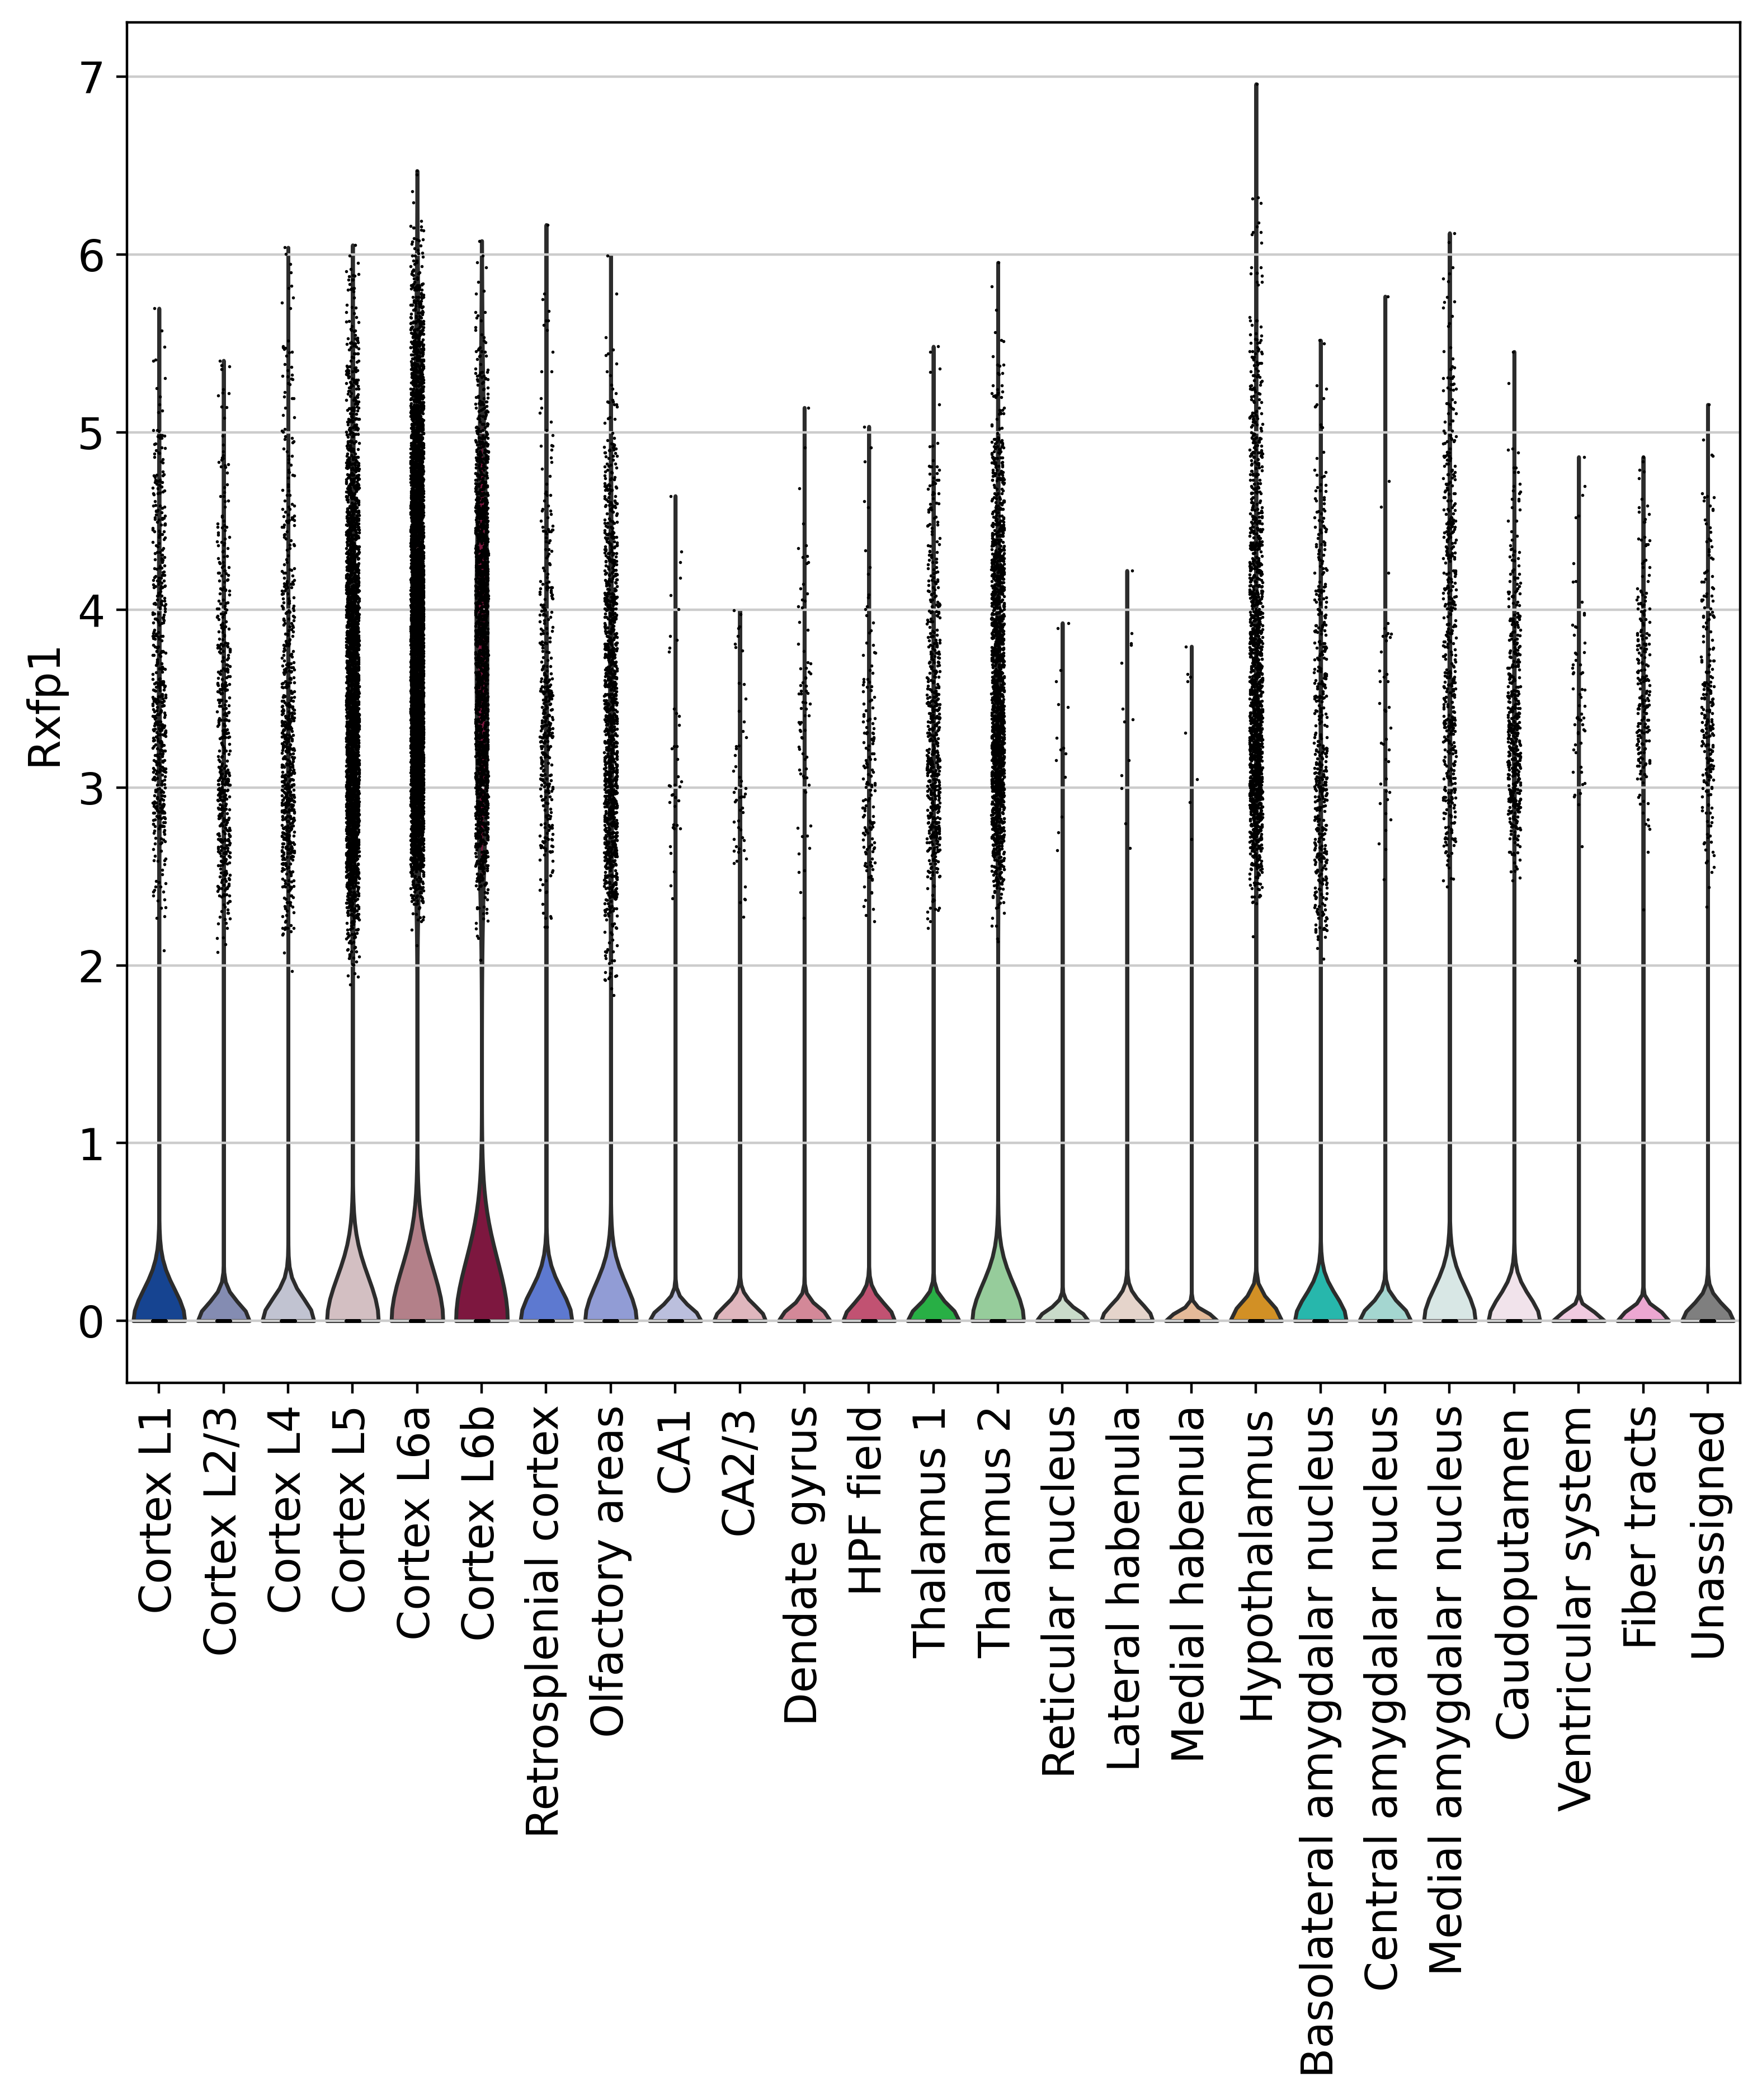

In [24]:
sc.pl.violin(adata,keys="Rxfp1",groupby="Region",rotation=90)